# Python EDA Assignment — What Drives Home-Loan Approval?
**Name:** Priyal Rana  **Roll No:** _<RollNo>_  **Programme:** PGDM, Great Lakes Institute of Management, Chennai

**Dataset:** Loan Prediction Problem Dataset (Dream Housing Finance) **Primary column:** `Loan_Status`

**Structure of this notebook**
- **A.** Dataset understanding and primary column
- **B.** Data preprocessing
- **C.** Univariate analysis
- **D.** Bivariate analysis
- **E.** Multivariate analysis
- **F.** Consolidated conclusion
- AI and source declaration

Each analysis step follows the order **Question → Code + output + chart → Insight**.

### Setup: import libraries and load the data
The dataset is stored in Google Drive at `/content/drive/MyDrive/Dataset.csv.xlsx`. (The file has a `.csv.xlsx` name, but it is actually an Excel file, so `pd.read_excel` is used.)

In [1]:
# Mount Google Drive so that Colab can read the dataset stored there
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats      # only used for statistical tests (chi-square, t-test, Mann-Whitney, correlation)

import warnings
warnings.filterwarnings('ignore')          # hide version warnings so outputs stay readable
pd.set_option('display.max_columns', None) # show every column when printing a dataframe
sns.set_style('whitegrid')

In [2]:
df=pd.read_excel(r"/content/drive/MyDrive/Dataset.csv.xlsx")
raw = df.copy()        # untouched copy of the original data, used later for before/after comparisons
print('Dataset loaded')

Dataset loaded


---
# Section A: Dataset understanding and primary column

### A1. Context
- **Name:** Loan Prediction Problem Dataset (training file `train_u6lujuX_CVtuZ9i`).
- **Kaggle link:** https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset
- **Source organisation:** Dream Housing Finance, an Indian housing-finance company that lends home loans in urban, semi-urban and rural areas. The data was shared publicly through the Analytics Vidhya *Loan Prediction* practice problem and is mirrored on Kaggle.
- **Time period:** The file has no date column, and the exact collection period is not published. It is a cross-sectional snapshot of past applications.
- **Real-world process:** A customer fills in an online home-loan application form (personal details, income, loan request, credit record). The company's credit team checks the application and either approves or rejects it.
- **One row:** One home-loan application and its final decision (`Loan_Status`).

### A2. Business problem
**Business question:** *Which applicant characteristics drive whether a home-loan application is approved, and which customer segments are being rejected most often?*

**Decision-maker:** The **Head of Retail Lending / Credit Policy** at Dream Housing Finance. They want to automate the eligibility check in real time (instant pre-approval on the website), so they need to know which fields really matter. They also need to know which segments the sales team should target and which ones need extra checks before a full application.

### A3. Data dictionary
**Question:** What does each column mean, how does pandas store it, and what type of variable is it?

In [3]:
print('Shape (rows, columns):', df.shape)
print()
df.info()

Shape (rows, columns): (614, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [4]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
# Data dictionary: my own meaning + classification for every column
meaning = {
 'Loan_ID':           'Unique application number',
 'Gender':            'Gender of the main applicant',
 'Married':           'Whether the applicant is married',
 'Dependents':        'Number of people financially dependent on the applicant',
 'Education':         'Graduate or not graduate',
 'Self_Employed':     'Whether the applicant runs own business (vs salaried)',
 'ApplicantIncome':   'Monthly income of the main applicant (Rs)',
 'CoapplicantIncome': 'Monthly income of the co-applicant, 0 if none (Rs)',
 'LoanAmount':        'Loan amount requested (Rs thousands)',
 'Loan_Amount_Term':  'Repayment period of the loan (months)',
 'Credit_History':    '1 = past credit meets guidelines, 0 = does not',
 'Property_Area':     'Location type of the property',
 'Loan_Status':       'Final decision: Y = approved, N = rejected (PRIMARY COLUMN)'
}
classification = {
 'Loan_ID': 'ID', 'Gender': 'Categorical nominal', 'Married': 'Categorical nominal',
 'Dependents': 'Categorical ordinal', 'Education': 'Categorical ordinal',
 'Self_Employed': 'Categorical nominal', 'ApplicantIncome': 'Numeric continuous',
 'CoapplicantIncome': 'Numeric continuous', 'LoanAmount': 'Numeric continuous',
 'Loan_Amount_Term': 'Numeric discrete', 'Credit_History': 'Categorical nominal (stored as 0/1)',
 'Property_Area': 'Categorical nominal', 'Loan_Status': 'Categorical nominal (binary target)'
}
data_dict = pd.DataFrame({
    'Column': df.columns,
    'Meaning': [meaning[c] for c in df.columns],
    'Pandas dtype': [str(df[c].dtype) for c in df.columns],
    'Classification': [classification[c] for c in df.columns],
    'Example value': [df[c].dropna().iloc[1] for c in df.columns]   # 2nd non-missing value of each column
})
data_dict

,Column,Meaning,Pandas dtype,Classification,Example value
0,Loan_ID,Unique application number,object,ID,LP001003
1,Gender,Gender of the main applicant,object,Categorical nominal,Male
2,Married,Whether the applicant is married,object,Categorical nominal,Yes
3,Dependents,Number of people financially dependent on the ...,object,Categorical ordinal,1
4,Education,Graduate or not graduate,object,Categorical ordinal,Graduate
5,Self_Employed,Whether the applicant runs own business (vs sa...,object,Categorical nominal,No
6,ApplicantIncome,Monthly income of the main applicant (Rs),int64,Numeric continuous,4583
7,CoapplicantIncome,"Monthly income of the co-applicant, 0 if none ...",float64,Numeric continuous,1508.0
8,LoanAmount,Loan amount requested (Rs thousands),float64,Numeric continuous,66.0
9,Loan_Amount_Term,Repayment period of the loan (months),float64,Numeric discrete,360.0


**Insight — A3: data dictionary**
- **Observation:** 614 rows × 13 columns. There are 5 numeric columns (4 genuinely numeric, plus `Credit_History`, which is a 0/1 flag stored as a float), 7 text columns and 1 ID column.
- **Hidden insight:** `info()` already shows that 7 columns have fewer than 614 non-null values, so preprocessing has real work to do. `Dependents` is stored as `object` because it mixes numbers (0, 1, 2) with the text "3+". `Credit_History` looks numeric but is really a yes/no category.
- **Business meaning:** Incomes are **monthly** and `LoanAmount` is in **₹ thousands**, so a value of 128 means ₹1.28 lakh. These units matter when comparing loan size to income.
- **Next step:** Fix types and units in Section B before analysing anything.

### A4. Primary column
**Question:** Which column is the outcome, and how is it distributed?

In [6]:
# Class balance of the primary column
print(df['Loan_Status'].value_counts())
print()
print((df['Loan_Status'].value_counts(normalize=True)*100).round(1))

Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan_Status
Y    68.7
N    31.3
Name: proportion, dtype: float64


**Primary column: `Loan_Status` (categorical, binary: Y = approved, N = rejected).**

This is the decision itself, so every other column is useful only if it helps explain it. For the Head of Credit Policy, knowing what moves `Loan_Status` means three things:
1. Building an instant pre-approval rule that does not reject good customers.
2. Cutting the cost of processing applications that will almost certainly be rejected.
3. Showing the sales team which segments convert best.

The classes are 68.7% approved and 31.3% rejected. The data is imbalanced but not extreme, so both groups have enough rows to compare.

### A5. Supporting columns and expectations

| # | Supporting column | Type | My expectation (before analysis) |
|---|---|---|---|
| 1 | `Credit_History` | Categorical | Applicants with a good credit history will be approved far more often than those with a bad one. |
| 2 | `ApplicantIncome` / `TotalIncome` | Numeric | Higher-income applicants will have a higher approval rate. |
| 3 | `LoanAmount` | Numeric | Larger loan requests will be rejected more often. |
| 4 | `CoapplicantIncome` | Numeric | Applications with a co-applicant who earns will be approved more often, because two incomes back the EMI. |
| 5 | `Property_Area` | Categorical | Urban properties will have the highest approval because their resale value and borrowers' incomes are higher. |
| 6 | `Education` | Categorical | Graduates will be approved more than non-graduates because their jobs are more stable. |
| 7 | `Married` | Categorical | Married applicants will be approved more because they usually have a second household income. |
| 8 | `Self_Employed` | Categorical | Self-employed applicants will be approved less because their income is irregular and harder to verify. |

**Columns I will drop or not use as drivers**
- `Loan_ID`: a unique ID for every row. It carries no information about the decision, so I drop it.
- `Gender`: kept in the data for the quality audit but **not used as a driver**. Fair-lending practice says gender should not influence credit decisions, so it is not a lever the decision-maker can or should act on.
- `Dependents`: kept, but treated as secondary, because its effect is likely to work through income per family member.
- **Leakage check:** no column is created after the decision (such as a disbursal date), so there is no leakage.

---
# Section B: Data preprocessing

### B1. Initial quality audit
**Question:** How large is the data, what are the types, are there duplicates, and where are the missing values? Is the missingness random or tied to a group?

In [7]:
print('Rows:', df.shape[0], '| Columns:', df.shape[1])
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Loan_IDs:', df['Loan_ID'].duplicated().sum())
print()
print(df.dtypes)

# Missing values per column, count and %
missing = pd.DataFrame({'Missing count': df.isnull().sum(),
                        'Missing %': (df.isnull().sum()/len(df)*100).round(2)})
missing = missing.sort_values('Missing count', ascending=False)
print()
print(missing)
print()
print('Rows with at least one missing value:', df.isnull().any(axis=1).sum(),
      f'({df.isnull().any(axis=1).mean()*100:.1f}% of rows)')

Rows: 614 | Columns: 13
Duplicate rows: 0
Duplicate Loan_IDs: 0

Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

                   Missing count  Missing %
Credit_History                50       8.14
Self_Employed                 32       5.21
LoanAmount                    22       3.58
Dependents                    15       2.44
Loan_Amount_Term              14       2.28
Gender                        13       2.12
Married                        3       0.49
Education                      0       0.00
Loan_ID                        0       0.00
CoapplicantIncome              0       0.00
ApplicantIncome                0       0.00
Property_Area  

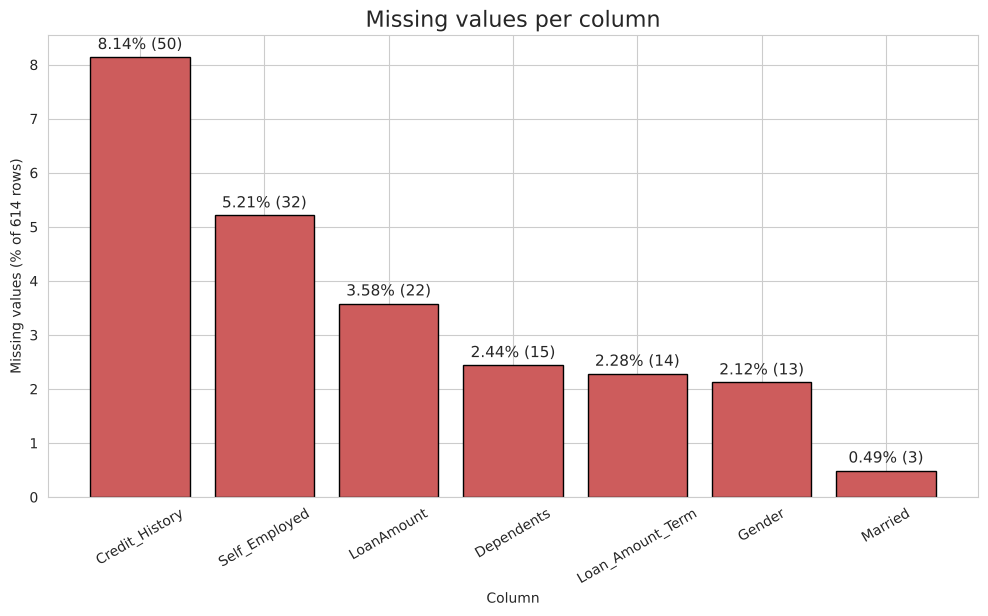

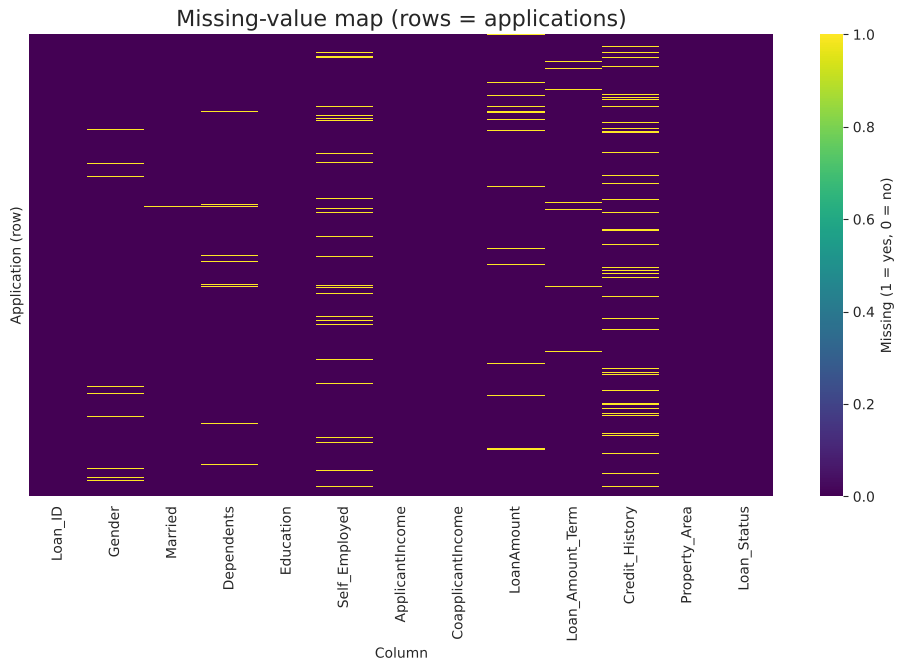

In [8]:
miss = missing[missing['Missing count']>0]      # keep only the affected columns

plt.figure(figsize=(12,6))
plt.bar(x=miss.index, height=miss['Missing %'], color='indianred', edgecolor='black')
for i, v in enumerate(miss['Missing %']):
    plt.text(i, v+0.15, f"{v}% ({miss['Missing count'].iloc[i]})", ha='center', fontsize=11)
plt.title('Missing values per column', fontsize=16)
plt.xlabel('Column')
plt.ylabel('Missing values (% of 614 rows)')
plt.xticks(rotation=30)
plt.show()

# Heatmap: each yellow line is one missing cell, so we can see if gaps cluster in the same rows
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis', yticklabels=False,
            cbar_kws={'label': 'Missing (1 = yes, 0 = no)'})
plt.title('Missing-value map (rows = applications)', fontsize=16)
plt.xlabel('Column')
plt.ylabel('Application (row)')
plt.show()

In [9]:
# Is missingness random or tied to the outcome? Compare approval % for rows where the value is missing vs present
rows = []
for col in miss.index:
    is_missing = df[col].isnull()
    rows.append([col, is_missing.sum(),
                 round((df.loc[is_missing, 'Loan_Status']=='Y').mean()*100, 1),
                 round((df.loc[~is_missing, 'Loan_Status']=='Y').mean()*100, 1)])
miss_vs_target = pd.DataFrame(rows, columns=['Column', 'Missing rows', 'Approval % when missing', 'Approval % when present'])
print(miss_vs_target)
print()
# Is Credit_History missing more often in one area?
print('Credit_History missing % by Property_Area:')
print((df.groupby('Property_Area')['Credit_History'].apply(lambda s: s.isnull().mean())*100).round(1))

             Column  Missing rows  Approval % when missing  \
0    Credit_History            50                     74.0   
1     Self_Employed            32                     71.9   
2        LoanAmount            22                     50.0   
3        Dependents            15                     60.0   
4  Loan_Amount_Term            14                     57.1   
5            Gender            13                     61.5   
6           Married             3                    100.0   

   Approval % when present  
0                     68.3  
1                     68.6  
2                     69.4  
3                     68.9  
4                     69.0  
5                     68.9  
6                     68.6  

Credit_History missing % by Property_Area:
Property_Area
Rural        7.8
Semiurban    6.9
Urban        9.9
Name: Credit_History, dtype: float64


**Insight — B1: initial quality audit**
- **Observation:** 614 rows, 13 columns, **0 duplicate rows and 0 duplicate Loan_IDs**. Seven columns have gaps. The biggest is `Credit_History` (50 rows, 8.1%), followed by `Self_Employed` (5.2%) and `LoanAmount` (3.6%). In total, 134 rows (21.8%) have at least one missing value, so dropping all of them would lose about a fifth of the data.
- **Hidden insight:** The heatmap shows the gaps are scattered rather than stacked in the same rows, so they look random across the file. However, missingness is **not neutral for the outcome**. Rows with missing `Credit_History` are approved 74.0% of the time against 68.3% for known ones, and rows with missing `LoanAmount` only 50.0% against 69.4%. Missing credit history is spread fairly evenly across areas (6.9–9.9%).
- **Business meaning:** A blank credit field is information in itself. It probably means a first-time borrower with no bureau record.
- **Next step:** Do not delete rows. Treat `Credit_History` separately.

### B2. Missing value treatment
**Question:** What is the right treatment for each affected column, and are the counts before and after correct?

In [10]:
before = df.isnull().sum()

# 1) Small categorical gaps (<6%) -> mode imputation (most frequent value)
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed']:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)
    print(f'{col}: filled with mode = {mode_value}')

# 2) Loan_Amount_Term is discrete and 83% of loans are 360 months -> mode
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])

# 3) LoanAmount is right-skewed -> median, calculated within Education x Self_Employed groups
#    (graduates and self-employed people ask for bigger loans, so one overall median would be biased)
print()
print('Median LoanAmount by group (used for filling):')
print(df.groupby(['Education','Self_Employed'])['LoanAmount'].median())
df['LoanAmount'] = df['LoanAmount'].fillna(df.groupby(['Education','Self_Employed'])['LoanAmount'].transform('median'))

# 4) Credit_History: the most important variable, 8% missing, and missing rows behave differently
#    -> keep them as a separate 'Unknown' category instead of guessing 1 or 0
df['Credit_History'] = df['Credit_History'].map({1.0: 'Good', 0.0: 'Bad'}).fillna('Unknown')

after = df.isnull().sum()
print()
print(pd.DataFrame({'Missing before': before, 'Missing after': after}))

Gender: filled with mode = Male
Married: filled with mode = Yes
Dependents: filled with mode = 0
Self_Employed: filled with mode = No

Median LoanAmount by group (used for filling):
Education     Self_Employed
Graduate      No               130.0
              Yes              157.5
Not Graduate  No               113.0
              Yes              130.0
Name: LoanAmount, dtype: float64

                   Missing before  Missing after
Loan_ID                         0              0
Gender                         13              0
Married                         3              0
Dependents                     15              0
Education                       0              0
Self_Employed                  32              0
ApplicantIncome                 0              0
CoapplicantIncome               0              0
LoanAmount                     22              0
Loan_Amount_Term               14              0
Credit_History                 50              0
Property_Area       

**Insight — B2: missing value treatment**
- **Observation:** All 149 missing cells are now filled, with 0 left and no rows lost.
  - **Mode** for `Gender`, `Married`, `Dependents` and `Self_Employed`: each is categorical, under 6% missing, and dominated by one level, so the mode is the safest guess.
  - **Mode (360)** for `Loan_Amount_Term`: 360 months covers about 85% of known loans.
  - **Group median** for `LoanAmount`: it is right-skewed, so I used the median rather than the mean. I took the median within Education × Self_Employed because the medians differ a lot (₹113k for non-graduate salaried vs ₹157.5k for self-employed graduates).
- **Hidden insight:** `Credit_History` is the column most linked to the outcome (tested in D2). Filling its gaps with the mode would have labelled 50 unknown applicants as "Good" and hidden a real segment, so I kept them as a third level, **"Unknown"**.
- **Business meaning:** The credit team can see how "no-record" applicants are treated.
- **Next step:** Check category spellings and data types.

### B3. Duplicates and inconsistencies
**Question:** Are there duplicate rows, inconsistent category labels, wrong data types or impossible values?

In [11]:
# Duplicates
print('Duplicate rows before:', df.duplicated().sum())
df = df.drop_duplicates()
print('Duplicate rows after :', df.duplicated().sum())
print()

# Inconsistent categories: remove extra spaces and check every distinct value
cat_cols = ['Gender','Married','Dependents','Education','Self_Employed','Property_Area','Loan_Status','Credit_History']
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()     # also makes Dependents one type (it mixed numbers 0,1,2 with text '3+')
    print(col, '->', sorted(df[col].unique()))
print()

# Wrong data types
print('Python types inside Dependents in the raw file:', raw['Dependents'].map(type).value_counts().to_dict())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].astype(int)        # months are whole numbers
df['Loan_Status'] = df['Loan_Status'].map({'Y': 'Approved', 'N': 'Rejected'})   # readable labels
print()

# Impossible values
print('Negative incomes:', (df['ApplicantIncome']<0).sum() + (df['CoapplicantIncome']<0).sum())
print('Zero or negative LoanAmount:', (df['LoanAmount']<=0).sum())
print('Loan terms present (months):', sorted(df['Loan_Amount_Term'].unique()))
print()
print('Applicants earning below Rs 1,000/month (suspicious, checked manually):')
print(df[df['ApplicantIncome']<1000][['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Status']])

Duplicate rows before: 0
Duplicate rows after : 0

Gender -> ['Female', 'Male']
Married -> ['No', 'Yes']
Dependents -> ['0', '1', '2', '3+']
Education -> ['Graduate', 'Not Graduate']
Self_Employed -> ['No', 'Yes']
Property_Area -> ['Rural', 'Semiurban', 'Urban']
Loan_Status -> ['N', 'Y']
Credit_History -> ['Bad', 'Good', 'Unknown']

Python types inside Dependents in the raw file: {<class 'int'>: 548, <class 'str'>: 51, <class 'float'>: 15}

Negative incomes: 0
Zero or negative LoanAmount: 0
Loan terms present (months): [np.int64(12), np.int64(36), np.int64(60), np.int64(84), np.int64(120), np.int64(180), np.int64(240), np.int64(300), np.int64(360), np.int64(480)]

Applicants earning below Rs 1,000/month (suspicious, checked manually):
     ApplicantIncome  CoapplicantIncome  LoanAmount Loan_Status
188              674             5296.0       168.0    Approved
216              150             1800.0       135.0    Rejected
468              210             2917.0        98.0    Approved

**Insight — B3: duplicates and inconsistencies**
- **Observation:** No duplicate rows. After stripping spaces, every categorical column has clean, consistently spelled levels (for example, only "Male"/"Female"). There are no negative incomes and no zero loan amounts.
- **Hidden insight:** The real type problems were hidden:
  - `Dependents` held **three Python types** in one column (548 integers, 51 strings "3+", 15 NaN). I converted it to one text category.
  - `Loan_Amount_Term` was a float, so I converted it to an integer number of months.
  - `Credit_History` (a 0/1 float) is now a labelled category.
  - `Loan_Status` Y/N has been recoded to Approved/Rejected so the charts are readable.
- **Possibly impossible values:** Five applicants earn under ₹1,000 a month. All five have a co-applicant earning ₹1,800–₹41,667, so they are probably dependent spouses or students applying with an earning partner. These are genuine, so I kept them.
- **Business meaning:** Applicant income alone understates repayment capacity, so household income is the better measure.
- **Next step:** Create `TotalIncome` (B5) and check outliers.

### B4. Outlier detection and treatment
**Question:** How many rows does the IQR rule flag in each key numeric column, and should they be removed?

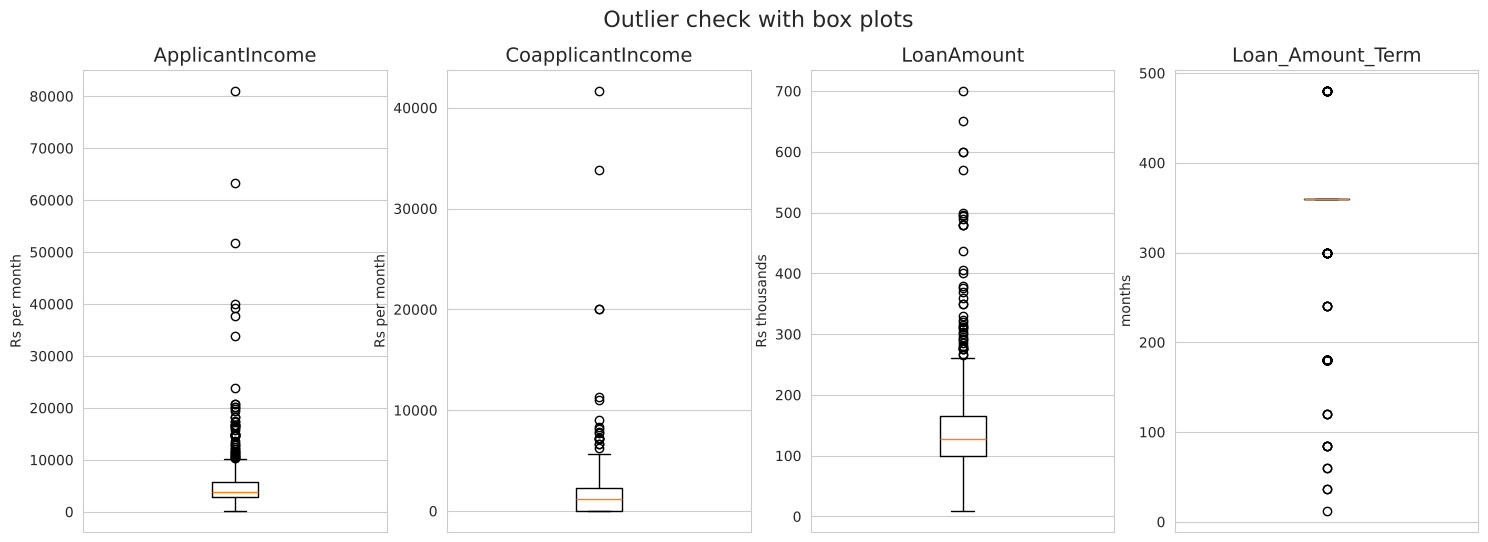

,Column,Q1,Q3,IQR,Lower fence,Upper fence,Rows flagged,% flagged
0,ApplicantIncome,2877.50,5795.00,2917.50,-1498.8,10171.2,50,8.1
1,CoapplicantIncome,0.00,2297.25,2297.25,-3445.9,5743.1,18,2.9
2,LoanAmount,100.25,164.75,64.50,3.5,261.5,41,6.7
3,Loan_Amount_Term,360.00,360.00,0.00,360.0,360.0,88,14.3


In [12]:
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

# Box plots of the key numeric columns
fig, axes = plt.subplots(1, 4, figsize=(18,6))
units = ['Rs per month', 'Rs per month', 'Rs thousands', 'months']
for i, col in enumerate(num_cols):
    axes[i].boxplot(df[col])
    axes[i].set_title(col, fontsize=14)
    axes[i].set_ylabel(units[i])
    axes[i].set_xticks([])
plt.suptitle('Outlier check with box plots', fontsize=16)
plt.show()

# IQR rule: outlier if value < Q1 - 1.5*IQR or > Q3 + 1.5*IQR
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    flagged = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, round(low,1), round(high,1), flagged, round(flagged/len(df)*100,1)])
outlier_table = pd.DataFrame(rows, columns=['Column','Q1','Q3','IQR','Lower fence','Upper fence','Rows flagged','% flagged'])
outlier_table

In [13]:
# Do the outliers behave differently on the primary column?
q3, q1 = df['ApplicantIncome'].quantile(0.75), df['ApplicantIncome'].quantile(0.25)
inc_out = df['ApplicantIncome'] > q3 + 1.5*(q3-q1)
q3, q1 = df['LoanAmount'].quantile(0.75), df['LoanAmount'].quantile(0.25)
loan_out = df['LoanAmount'] > q3 + 1.5*(q3-q1)

print('Approval % - income outliers:', round((df.loc[inc_out,'Loan_Status']=='Approved').mean()*100,1),
      '| others:', round((df.loc[~inc_out,'Loan_Status']=='Approved').mean()*100,1))
print('Approval % - loan amount outliers:', round((df.loc[loan_out,'Loan_Status']=='Approved').mean()*100,1),
      '| others:', round((df.loc[~loan_out,'Loan_Status']=='Approved').mean()*100,1))

# Treatment: keep all rows, but add a flag column so they can be filtered if needed
df['Income_Outlier'] = np.where(inc_out, 'Yes', 'No')
print()
print('Rows kept:', len(df))

Approval % - income outliers: 66.0 | others: 69.0
Approval % - loan amount outliers: 61.0 | others: 69.3

Rows kept: 614


**Insight — B4: outlier detection and treatment**
- **Observation:** The IQR rule flags:
  - `ApplicantIncome`: 50 rows (8.1%), above ₹10,171 a month.
  - `LoanAmount`: 41 rows (6.7%), above ₹261.5k.
  - `CoapplicantIncome`: 18 rows (2.9%).
  - `Loan_Amount_Term`: 88 rows (14.3%). This is misleading. Q1 = Q3 = 360, so the IQR is 0 and *every* non-360 term gets flagged. The IQR rule does not work for a discrete column dominated by one value.
- **Hidden insight:** The outliers are approved at almost the same rate as everyone else (income outliers 66.0% vs 69.0%; large loans 61.0% vs 69.3%). They are real high earners and big-ticket borrowers, not typing errors.
- **Treatment:** I **keep all rows** and add an `Income_Outlier` flag. Deleting 8% of applicants would bias the data towards average customers. Instead, the charts use **log scales** and the tests use **medians or non-parametric tests** (Mann-Whitney, Spearman), which are not distorted by extreme values.
- **Next step:** Create the affordability features.

### B5. Feature creation (supports the B6 summary)
**Question:** Which new columns would explain approval better than the raw fields?

In [14]:
# New columns that help explain the primary column
df['TotalIncome'] = df['ApplicantIncome'] + df['CoapplicantIncome']             # household income, Rs per month
df['EMI'] = (df['LoanAmount']*1000 / df['Loan_Amount_Term']).round(0)           # simple monthly instalment (no interest), Rs
df['EMI_to_Income'] = (df['EMI'] / df['TotalIncome'] * 100).round(2)            # % of monthly income needed for the EMI
df['Has_Coapplicant'] = np.where(df['CoapplicantIncome']>0, 'Yes', 'No')
df['Approved'] = np.where(df['Loan_Status']=='Approved', 1, 0)                  # 1/0 version of the primary column (for rates)
df['Income_Band'] = pd.qcut(df['TotalIncome'], q=4,                             # 4 equal-size income groups
                            labels=['Q1 Low','Q2 Lower-mid','Q3 Upper-mid','Q4 High'])

# Drop the ID column (unique per row, no information about the decision)
df = df.drop(columns=['Loan_ID'])

df[['ApplicantIncome','CoapplicantIncome','TotalIncome','LoanAmount','Loan_Amount_Term','EMI','EMI_to_Income','Approved']].head()

,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,Loan_Amount_Term,EMI,EMI_to_Income,Approved
0,5849,0.0,5849.0,130.0,360,361.0,6.17,1
1,4583,1508.0,6091.0,128.0,360,356.0,5.84,0
2,3000,0.0,3000.0,66.0,360,183.0,6.10,1
3,2583,2358.0,4941.0,120.0,360,333.0,6.74,1
4,6000,0.0,6000.0,141.0,360,392.0,6.53,1


**Insight — B5: feature creation**
- **`TotalIncome`** = applicant + co-applicant income, because lenders assess household repayment capacity (see B3).
- **`EMI`** = loan amount (₹) ÷ term in months. This is a simple **interest-free** instalment, so it understates the true EMI. It is still useful for *comparing* burden between applicants.
- **`EMI_to_Income`** = EMI as % of monthly household income. This is a proxy for the FOIR (fixed-obligation-to-income ratio) that banks use.
- **`Has_Coapplicant`**, the **`Approved` (1/0)** version of the primary column (so approval *rates* can be averaged), and **`Income_Band`** (income quartiles).

None of these is scaled or encoded for modelling. They exist only to make the charts and comparisons clearer.

### B6. Final clean dataset summary
**Question:** What does the final dataset look like, and how much of the original did we keep?

In [15]:
print('Final shape:', df.shape)
df.describe().round(2)

Final shape: (614, 19)


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,TotalIncome,EMI,EMI_to_Income,Approved
count,614.00,614.00,614.00,614.00,614.00,614.00,614.00,614.00
mean,5403.46,1621.25,145.76,342.41,7024.71,473.58,7.73,0.69
std,6109.04,2926.25,84.15,64.43,6458.66,511.04,7.89,0.46
min,150.00,0.00,9.00,12.00,1442.00,25.00,0.70,0.00
25%,2877.50,0.00,100.25,360.00,4166.00,289.00,5.55,0.00
50%,3812.50,1188.50,128.00,360.00,5416.50,361.00,6.89,1.00
75%,5795.00,2297.25,164.75,360.00,7521.75,506.00,8.17,1.00
max,81000.00,41667.00,700.00,480.00,81000.00,9250.00,123.70,1.00


In [16]:
df.describe(include='object')

,Gender,Married,Dependents,Education,Self_Employed,Credit_History,Property_Area,Loan_Status,Income_Outlier,Has_Coapplicant
count,614,614,614,614,614,614,614,614,614,614
unique,2,2,4,2,2,3,3,2,2,2
top,Male,Yes,0,Graduate,No,Good,Semiurban,Approved,No,Yes
freq,502,401,360,480,532,475,233,422,564,341


In [17]:
summary = pd.DataFrame({
    'Item': ['Original rows', 'Rows removed', 'Final rows', '% of rows retained',
             'Original columns', 'Columns dropped', 'Columns created', 'Final columns', 'Missing cells left'],
    'Value': [raw.shape[0], raw.shape[0]-df.shape[0], df.shape[0], f'{df.shape[0]/raw.shape[0]*100:.1f}%',
              raw.shape[1], 'Loan_ID (1)',
              'Income_Outlier, TotalIncome, EMI, EMI_to_Income, Has_Coapplicant, Approved, Income_Band (7)',
              df.shape[1], df.isnull().sum().sum()]
})
summary

,Item,Value
0,Original rows,614
1,Rows removed,0
2,Final rows,614
3,% of rows retained,100.0%
4,Original columns,13
5,Columns dropped,Loan_ID (1)
6,Columns created,"Income_Outlier, TotalIncome, EMI, EMI_to_Incom..."
7,Final columns,19
8,Missing cells left,0


**Insight — B6: final clean dataset**
- **Observation:** The final data is **614 rows × 19 columns, with 100% of rows retained** and 0 missing cells. One column was dropped (`Loan_ID`) and 7 were created.
- **Key numbers:**
  - Median household income is ₹5,417 a month, but the mean is ₹7,025, which already signals right skew.
  - Median loan is ₹128k.
  - Median EMI burden is only 6.9% of income (interest-free), but the maximum is 123.7%.
  - On the categorical side, Male (82%), Married (65%), Graduate (78%), Not self-employed (87%) and Good credit (77%) dominate.
- **Hidden insight:** Most applicants look similar on paper (salaried, married graduates borrowing about ₹1.3 lakh on a 30-year term). That means any big difference in approval must come from a few columns, not from the profile as a whole.
- **Next step:** Look at each variable on its own.

---
# Section C: Univariate analysis

In [18]:
# Small helper so every numeric column gets the same summary statistics
def num_summary(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return pd.Series({'Mean': s.mean(), 'Median': s.median(), 'Mode': s.mode()[0], 'SD': s.std(),
                      'IQR': iqr, 'Min': s.min(), 'Max': s.max(), 'Skewness': s.skew(), 'Kurtosis': s.kurt(),
                      'Outliers (IQR)': ((s < q1-1.5*iqr) | (s > q3+1.5*iqr)).sum()}).round(2)
print('helper ready')

helper ready


### C1. Primary column: `Loan_Status`
**Question:** How balanced is the approval decision?

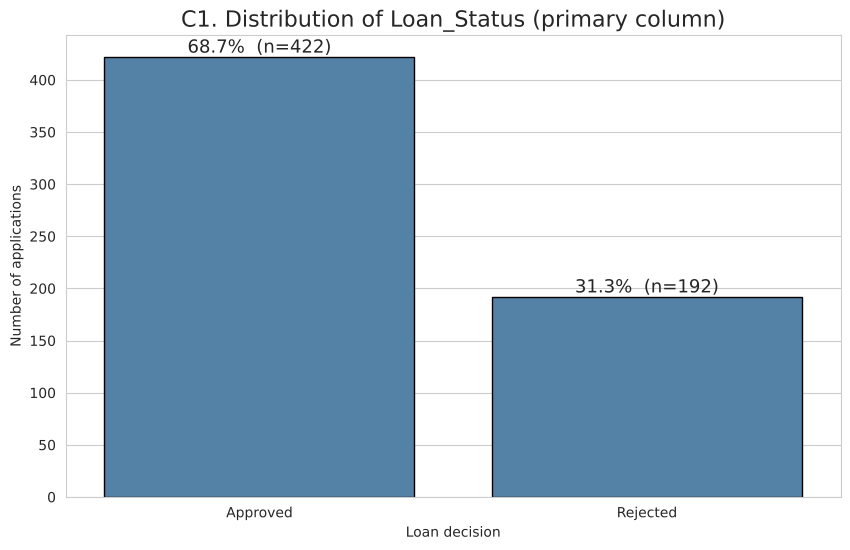

Loan_Status
Approved    68.7
Rejected    31.3
Name: proportion, dtype: float64
Ratio approved : rejected = 2.2 : 1


In [19]:
plt.figure(figsize=(10,6))
ax = sns.countplot(x='Loan_Status', data=df, order=['Approved','Rejected'], color='steelblue', edgecolor='black')
for p in ax.patches:     # write the % on top of each bar
    ax.annotate(f'{p.get_height()/len(df)*100:.1f}%  (n={int(p.get_height())})',
                (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=13)
plt.title('C1. Distribution of Loan_Status (primary column)', fontsize=16)
plt.xlabel('Loan decision')
plt.ylabel('Number of applications')
plt.show()

print((df['Loan_Status'].value_counts(normalize=True)*100).round(1))
print('Ratio approved : rejected =', round((df['Approved']==1).sum()/(df['Approved']==0).sum(), 2), ': 1')

**Insight — C1: Loan_Status**
- **Observation:** 422 applications approved (68.7%) and 192 rejected (31.3%), a ratio of 2.2 : 1. The variable is binary, so there are no outliers or gaps.
- **Hidden insight:** Roughly **1 in 3 applications is rejected**, so a large share of the company's processing cost goes into files that end in a "no". Also, a naïve rule of "approve everyone" would already be right 68.7% of the time. Any driver I find has to beat that baseline to be useful.
- **Business meaning:** For the Head of Credit Policy, the opportunity is to spot the likely rejections *before* full processing, and to make sure good applicants are not lost among them.
- **Next step:** In the bivariate section, find which columns separate the 31% rejected from the 69% approved.

### C2. Numeric supporting column: `ApplicantIncome`
**Question:** What is the shape, centre and spread of applicant income?

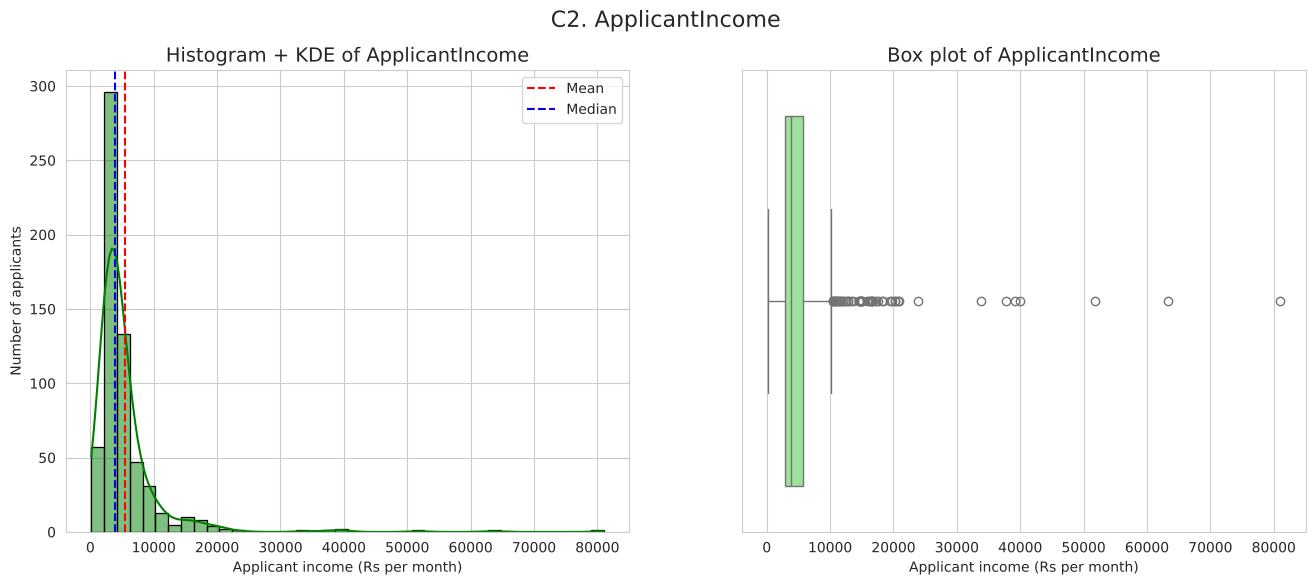

Mean               5403.46
Median             3812.50
Mode               2500.00
SD                 6109.04
IQR                2917.50
Min                 150.00
Max               81000.00
Skewness              6.54
Kurtosis             60.54
Outliers (IQR)       50.00
dtype: float64

Share of applicants above Rs 10,000/month: 8.5 %
Top 10% of applicants hold 33.1 % of all applicant income


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))
sns.histplot(df['ApplicantIncome'], kde=True, bins=40, color='green', edgecolor='black', ax=axes[0])
axes[0].axvline(df['ApplicantIncome'].mean(), color='red', linestyle='--', label='Mean')
axes[0].axvline(df['ApplicantIncome'].median(), color='blue', linestyle='--', label='Median')
axes[0].set_title('Histogram + KDE of ApplicantIncome', fontsize=14)
axes[0].set_xlabel('Applicant income (Rs per month)')
axes[0].set_ylabel('Number of applicants')
axes[0].legend()

sns.boxplot(x=df['ApplicantIncome'], color='lightgreen', ax=axes[1])
axes[1].set_title('Box plot of ApplicantIncome', fontsize=14)
axes[1].set_xlabel('Applicant income (Rs per month)')
plt.suptitle('C2. ApplicantIncome', fontsize=16)
plt.show()

print(num_summary(df['ApplicantIncome']))
print()
print('Share of applicants above Rs 10,000/month:', round((df['ApplicantIncome']>10000).mean()*100,1), '%')
print('Top 10% of applicants hold', round(df['ApplicantIncome'].nlargest(int(len(df)*0.1)).sum()/df['ApplicantIncome'].sum()*100,1), '% of all applicant income')

**Insight — C2: ApplicantIncome**
- **Observation:** Strongly **right-skewed** (skewness 6.54, kurtosis 60.5). The mean of ₹5,403 is 42% above the median of ₹3,813 because a long tail stretches to ₹81,000. The IQR is ₹2,918, and 50 rows (8.1%) are outliers. The mode is a round ₹2,500, and spikes at round numbers suggest some incomes are self-reported.
- **Hidden insight:** Income is very concentrated: the **top 10% of applicants hold 33.1% of all applicant income**. The "average applicant" described by the mean does not exist. A typical applicant earns under ₹4,000 a month.
- **Business meaning:** Any income cut-off in a pre-approval rule should use the median or bands, never the mean.
- **Next step:** Test whether income actually differs between approved and rejected applicants (D3), using household `TotalIncome`.

### C3. Numeric supporting column: `LoanAmount`
**Question:** How large are the loans that customers request?

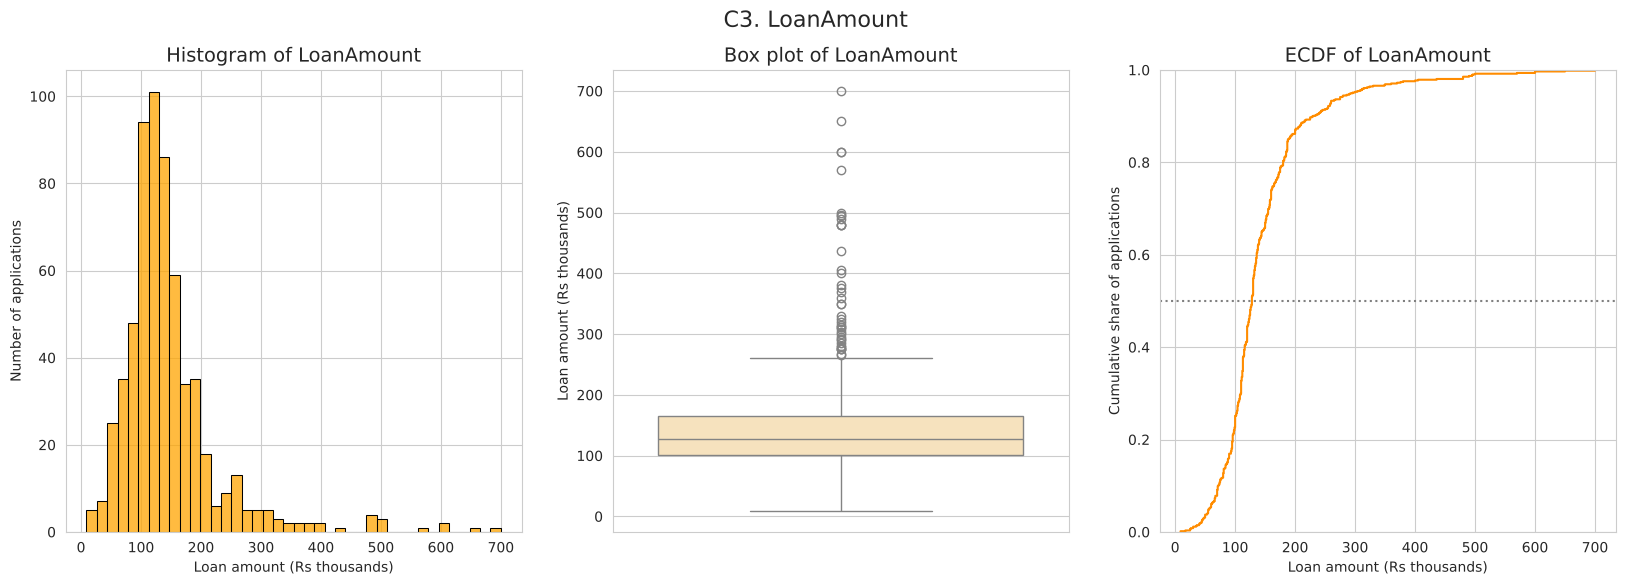

Mean              145.76
Median            128.00
Mode              130.00
SD                 84.15
IQR                64.50
Min                 9.00
Max               700.00
Skewness            2.74
Kurtosis           10.91
Outliers (IQR)     41.00
dtype: float64

Share of loans between Rs 100k and Rs 200k: 64.3 %
Most common exact amounts: {130.0: 22, 120.0: 20, 113.0: 18, 110.0: 17, 100.0: 15}


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20,6))
sns.histplot(df['LoanAmount'], bins=40, color='orange', edgecolor='black', ax=axes[0])
axes[0].set_title('Histogram of LoanAmount', fontsize=14)
axes[0].set_xlabel('Loan amount (Rs thousands)')
axes[0].set_ylabel('Number of applications')

sns.boxplot(y=df['LoanAmount'], color='moccasin', ax=axes[1])
axes[1].set_title('Box plot of LoanAmount', fontsize=14)
axes[1].set_ylabel('Loan amount (Rs thousands)')

sns.ecdfplot(df['LoanAmount'], color='darkorange', ax=axes[2])
axes[2].axhline(0.5, color='grey', linestyle=':')
axes[2].set_title('ECDF of LoanAmount', fontsize=14)
axes[2].set_xlabel('Loan amount (Rs thousands)')
axes[2].set_ylabel('Cumulative share of applications')
plt.suptitle('C3. LoanAmount', fontsize=16)
plt.show()

print(num_summary(df['LoanAmount']))
print()
print('Share of loans between Rs 100k and Rs 200k:', round(df['LoanAmount'].between(100,200).mean()*100,1), '%')
print('Most common exact amounts:', df['LoanAmount'].value_counts().head(5).to_dict())

**Insight — C3: LoanAmount**
- **Observation:** **Right-skewed** (skewness 2.74), but much less than income. The median is ₹128k and the mean ₹146k. The IQR runs from ₹100k to ₹165k, and 41 loans (6.7%) exceed ₹261.5k, up to ₹700k.
- **Hidden insight:**
  - The ECDF rises very steeply: **64.3% of all loans sit between ₹100k and ₹200k**. The product is concentrated in a narrow ticket band.
  - Round numbers (₹120k, ₹100k, ₹110k) and the imputed ₹130k/₹113k medians appear as small spikes.
  - The minimum of ₹9k is unusually small for a home loan. It could be a top-up loan, so I kept it.
- **Business meaning:** Large tickets are rare, so the lender's risk is spread across many similar mid-sized loans.
- **Next step:** Check whether bigger loans are rejected more often (D4), and whether loan size follows income (D1).

### C4. Categorical supporting column: `Property_Area`
**Question:** Where are the properties located?

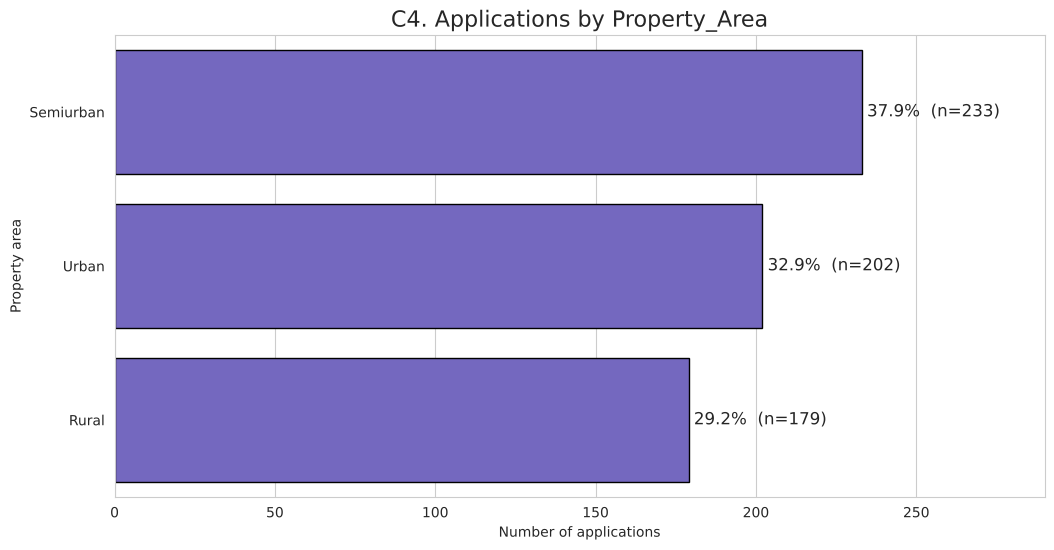

               Count     %
Property_Area             
Semiurban        233  37.9
Urban            202  32.9
Rural            179  29.2
Number of levels: 3 | Dominant level: Semiurban


In [22]:
order = df['Property_Area'].value_counts().index        # sort bars by frequency
plt.figure(figsize=(12,6))
ax = sns.countplot(y='Property_Area', data=df, order=order, color='slateblue', edgecolor='black')
for p in ax.patches:
    ax.annotate(f' {p.get_width()/len(df)*100:.1f}%  (n={int(p.get_width())})',
                (p.get_width(), p.get_y()+p.get_height()/2), va='center', fontsize=12)
plt.title('C4. Applications by Property_Area', fontsize=16)
plt.xlabel('Number of applications')
plt.ylabel('Property area')
plt.xlim(0, 290)
plt.show()

freq = pd.DataFrame({'Count': df['Property_Area'].value_counts(),
                     '%': (df['Property_Area'].value_counts(normalize=True)*100).round(1)})
print(freq)
print('Number of levels:', df['Property_Area'].nunique(), '| Dominant level:', freq.index[0])

**Insight — C4: Property_Area**
- **Observation:** Three levels that are **fairly balanced**: Semiurban 37.9% (233), Urban 32.9% (202), Rural 29.2% (179). No level is rare, so comparisons between areas are reliable.
- **Hidden insight:** Semi-urban is the **largest** segment, ahead of Urban. For a housing-finance company, this suggests demand is strongest on the fringes of cities, where new housing is being built, rather than in city centres.
- **Business meaning:** If semi-urban applicants also turn out to be approved more often, that is the core market for the sales team.
- **Next step:** Compare approval rates across the three areas (D5).

### C5. (Optional) Categorical: `Credit_History`
**Question:** How many applicants meet the credit guidelines?

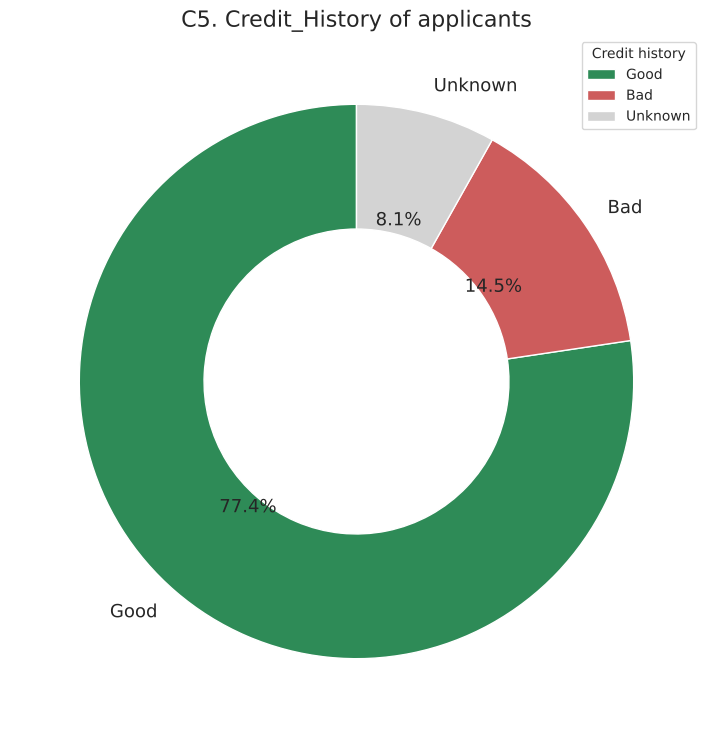

Credit_History
Good       475
Bad         89
Unknown     50
Name: count, dtype: int64


In [23]:
counts = df['Credit_History'].value_counts()
plt.figure(figsize=(9,9))
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=90,
        colors=['seagreen','indianred','lightgrey'], wedgeprops={'edgecolor':'white','width':0.45},
        textprops={'fontsize':13})          # width < 1 turns the pie into a donut
plt.title('C5. Credit_History of applicants', fontsize=16)
plt.legend(title='Credit history', loc='upper right')
plt.show()

print(counts)

**Insight — C5: Credit_History**
- **Observation:** **Dominated by one level.** 77.4% have a Good history (475), 14.5% Bad (89) and 8.1% Unknown (50, created in B2). There are only 3 levels, so a donut chart is suitable.
- **Hidden insight:** 1 in 7 applicants already fails the credit guideline before income is even considered. The "Unknown" group (8%) is a meaningful segment, not a rounding error.
- **Business meaning:** If credit history drives approval, the company could check the credit bureau *first* and stop wasting processing effort on the 14.5% who will probably be rejected.
- **Next step:** Cross-tab with `Loan_Status` (D2).

### C6. (Optional) Numeric: `CoapplicantIncome`
**Question:** How common is a co-applicant, and how much do co-applicants earn?

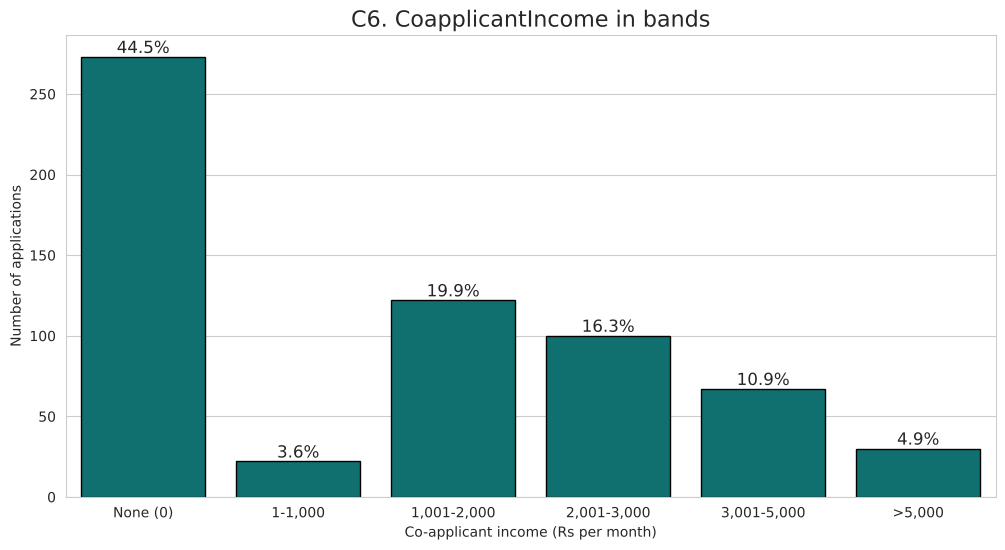

Mean               1621.25
Median             1188.50
Mode                  0.00
SD                 2926.25
IQR                2297.25
Min                   0.00
Max               41667.00
Skewness              7.49
Kurtosis             84.96
Outliers (IQR)       18.00
dtype: float64

Median co-applicant income among those who HAVE one: 2166.0


In [24]:
# Bin co-applicant income; 0 gets its own bar because "no co-applicant" is a different situation
bins = [-1, 0, 1000, 2000, 3000, 5000, 50000]
labels = ['None (0)', '1-1,000', '1,001-2,000', '2,001-3,000', '3,001-5,000', '>5,000']
df['Coapp_Band'] = pd.cut(df['CoapplicantIncome'], bins=bins, labels=labels)

plt.figure(figsize=(12,6))
ax = sns.countplot(x='Coapp_Band', data=df, color='teal', edgecolor='black')
for p in ax.patches:
    ax.annotate(f'{p.get_height()/len(df)*100:.1f}%', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=12)
plt.title('C6. CoapplicantIncome in bands', fontsize=16)
plt.xlabel('Co-applicant income (Rs per month)')
plt.ylabel('Number of applications')
plt.show()

print(num_summary(df['CoapplicantIncome']))
print()
print('Median co-applicant income among those who HAVE one:', df.loc[df['CoapplicantIncome']>0, 'CoapplicantIncome'].median())

**Insight — C6: CoapplicantIncome**
- **Observation:** **Bimodal-like with a huge spike at zero.** 44.5% of applications have no co-applicant income, so the mode is 0. Among those who have one, the median is ₹2,166. Skewness is 7.49, with 18 outliers up to ₹41,667.
- **Hidden insight:** Co-applicants usually earn *less* than the main applicant. Their typical ₹2,166 is about 57% of the median applicant income, so they top up income rather than replace it. The zero spike is a real situation (a single earner), not missing data.
- **Business meaning:** A co-applicant could be the difference for a low-income applicant who would fail alone.
- **Next step:** Test whether a co-applicant raises approval (D6), and whether that depends on how much the main applicant earns (E1).

### C-final. Univariate summary
- **Loan_Status:** 68.7% approved vs 31.3% rejected (2.2 : 1). Any useful driver must beat a 68.7% "approve all" baseline.
- **ApplicantIncome:** Extremely right-skewed (skew 6.5, mean 42% above median), with the top 10% holding a third of all income. Use medians, bands and log scales.
- **LoanAmount:** Moderately right-skewed, with 64% of loans in the narrow ₹100k–₹200k band. The product is fairly standardised.
- **CoapplicantIncome:** 44.5% have none. When present it is a smaller top-up (median ₹2,166).
- **Property_Area:** Balanced across three areas, with Semiurban the largest (37.9%).
- **Credit_History:** Dominated by Good (77%), but 14.5% Bad and 8.1% Unknown. This is the most likely single driver to test first.

---
# Section D: Bivariate analysis
My primary column is **categorical**, so D2 tests it against a categorical driver, and D3/D4 compare numeric drivers across the Approved and Rejected classes. D1 checks the relationship between the two main numeric drivers.

### D1. Numeric × Numeric: `TotalIncome` vs `LoanAmount` (+ correlation heatmap)
**Question:** Do people with higher income ask for bigger loans, and does any numeric column correlate with approval?

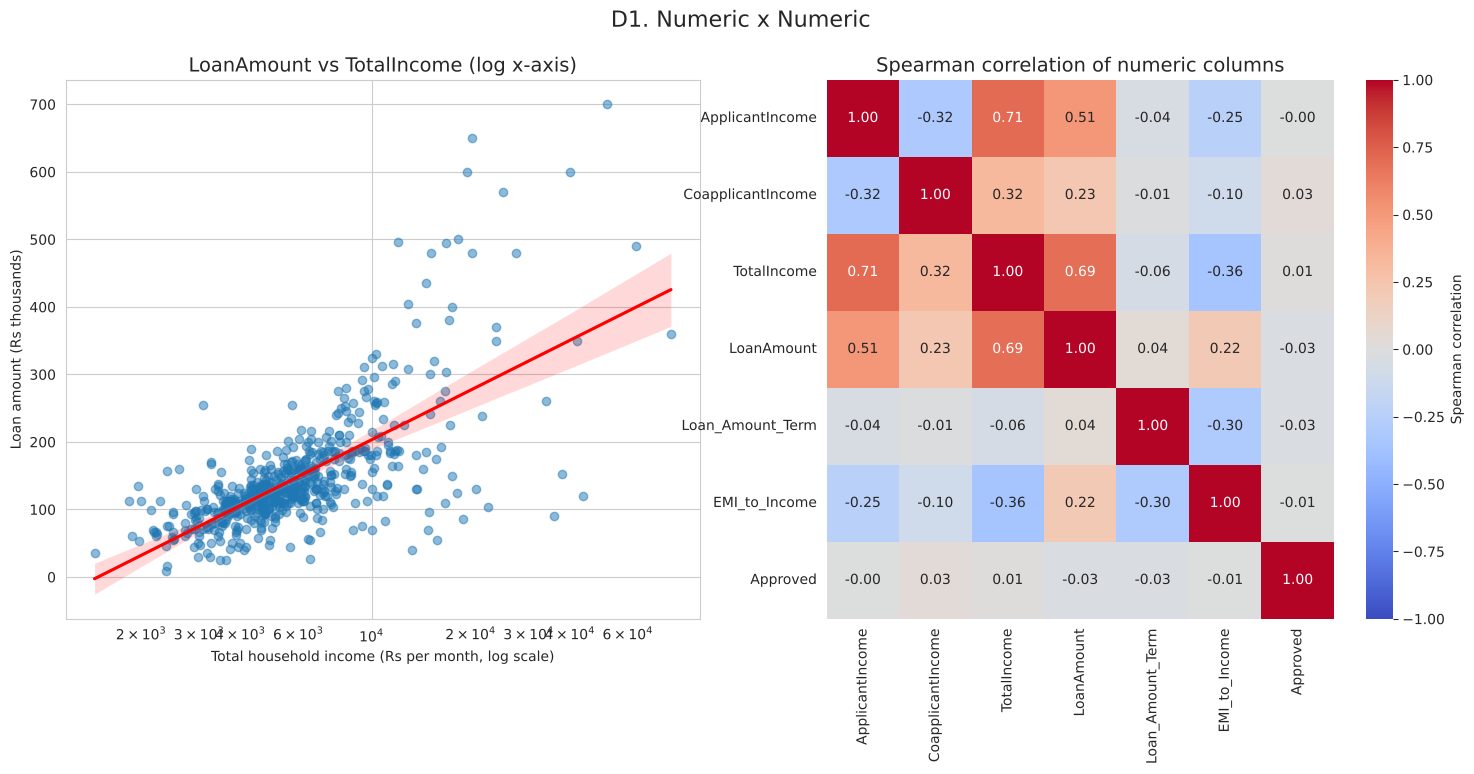

TotalIncome vs LoanAmount  ->  Pearson r = 0.621 (p = 1.24e-66),  Spearman rho = 0.690 (p = 6.80e-88)
ApplicantIncome vs LoanAmount -> Pearson r = 0.566
log(TotalIncome) vs log(LoanAmount) -> Pearson r = 0.660


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18,7))
sns.regplot(x='TotalIncome', y='LoanAmount', data=df, logx=True, scatter_kws={'alpha':0.5}, line_kws={'color':'red'}, ax=axes[0])  # logx=True fits the trend on log(income)
axes[0].set_xscale('log')                       # log scale so the few very rich applicants do not squash the rest
axes[0].set_title('LoanAmount vs TotalIncome (log x-axis)', fontsize=14)
axes[0].set_xlabel('Total household income (Rs per month, log scale)')
axes[0].set_ylabel('Loan amount (Rs thousands)')

corr_cols = ['ApplicantIncome','CoapplicantIncome','TotalIncome','LoanAmount','Loan_Amount_Term','EMI_to_Income','Approved']
sns.heatmap(df[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            ax=axes[1], cbar_kws={'label': 'Spearman correlation'})
axes[1].set_title('Spearman correlation of numeric columns', fontsize=14)
plt.suptitle('D1. Numeric x Numeric', fontsize=16)
plt.show()

r_p, p_p = stats.pearsonr(df['TotalIncome'], df['LoanAmount'])
r_s, p_s = stats.spearmanr(df['TotalIncome'], df['LoanAmount'])
print(f'TotalIncome vs LoanAmount  ->  Pearson r = {r_p:.3f} (p = {p_p:.2e}),  Spearman rho = {r_s:.3f} (p = {p_s:.2e})')
r_p2, _ = stats.pearsonr(df['ApplicantIncome'], df['LoanAmount'])
print(f'ApplicantIncome vs LoanAmount -> Pearson r = {r_p2:.3f}')
r_p3, _ = stats.pearsonr(np.log(df['TotalIncome']), np.log(df['LoanAmount']))
print(f'log(TotalIncome) vs log(LoanAmount) -> Pearson r = {r_p3:.3f}')

**Insight — D1: TotalIncome × LoanAmount**
- **Observation:** There is a **strong positive** relationship. Pearson r = 0.62 and Spearman ρ = 0.69, with p < 0.001 for both. Spearman is higher than Pearson and log-log r rises to 0.66, so the form is **monotonic but curved**: loan size grows more slowly than income at the top end.
- **Hidden insight:** In the heatmap, the `Approved` row is close to **zero for every numeric column** (Spearman between −0.03 and +0.03). Income and loan size are tightly linked to *each other*, but neither is linked to approval. Applicants already size their loan to their income before they apply.
- **Business meaning:** Income and loan amount alone cannot be the basis of the pre-approval rule.
- **Next step:** Look for the driver in the categorical columns (D2), and check whether affordability matters within credit groups (E3).

### D2. Categorical × Categorical: `Credit_History` × `Loan_Status`
**Question:** How much does credit history change the chance of approval?

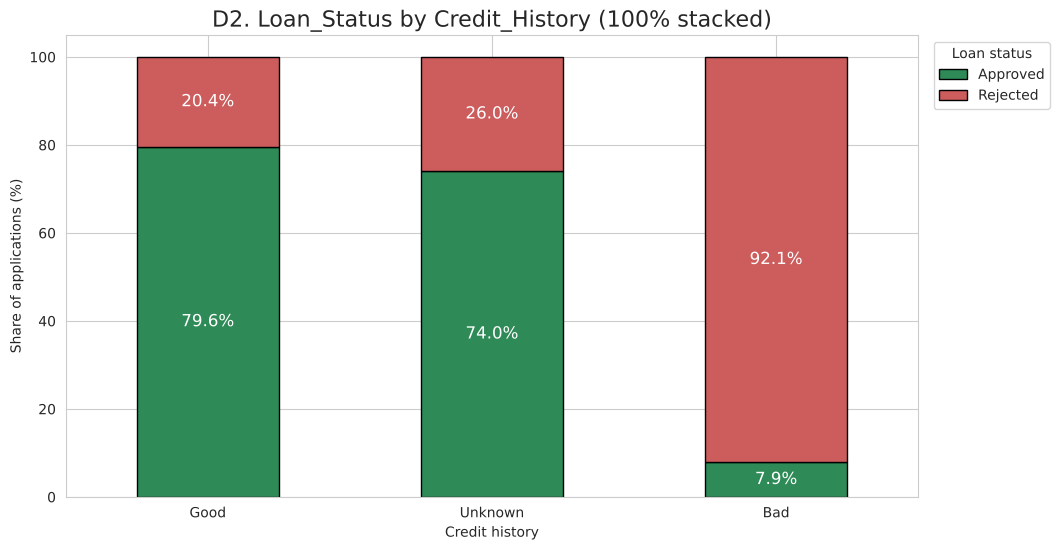

Counts:
Loan_Status     Approved  Rejected
Credit_History                    
Good                 378        97
Unknown               37        13
Bad                    7        82

Row %:
Loan_Status     Approved  Rejected
Credit_History                    
Good                79.6      20.4
Unknown             74.0      26.0
Bad                  7.9      92.1

Chi-square = 180.1, dof = 2, p-value = 7.93e-40, Cramer's V = 0.54


In [26]:
ct = pd.crosstab(df['Credit_History'], df['Loan_Status'])
ct_pct = pd.crosstab(df['Credit_History'], df['Loan_Status'], normalize='index')*100   # row %
ct_pct = ct_pct.loc[['Good','Unknown','Bad']]

ax = ct_pct.plot(kind='bar', stacked=True, figsize=(11,6), color=['seagreen','indianred'], edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', label_type='center', fontsize=12, color='white')
plt.title('D2. Loan_Status by Credit_History (100% stacked)', fontsize=16)
plt.xlabel('Credit history')
plt.ylabel('Share of applications (%)')
plt.xticks(rotation=0)
plt.legend(title='Loan status', bbox_to_anchor=(1.01,1))
plt.show()

print('Counts:'); print(ct.loc[['Good','Unknown','Bad']])
print(); print('Row %:'); print(ct_pct.round(1))
chi2, p, dof, exp = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape)-1)))     # effect size, 0 = none, 1 = perfect
print(f'\nChi-square = {chi2:.1f}, dof = {dof}, p-value = {p:.2e}, Cramer\'s V = {cramers_v:.2f}')

**Insight — D2: Credit_History × Loan_Status**
- **Observation:** The relationship is **very strong**: χ² = 180.1, p ≈ 8×10⁻⁴⁰, Cramér's V = 0.54. Good credit is approved **79.6%** of the time, Bad credit only **7.9%** (7 of 89). This is a gap of 72 percentage points, and a bad history makes approval about 10 times less likely.
- **Hidden insight:**
  - The **"Unknown"** group (74.0%) behaves almost like Good, not like Bad. The lender seems to give first-time borrowers the benefit of the doubt, which confirms the decision in B2 to keep them separate.
  - Even with Good credit, 1 in 5 (97 applicants) is still rejected. Credit history is necessary but not sufficient.
- **Business meaning:** A bureau check at the first step would identify 92% of the Bad-history group as rejections before full processing.
- **Next step:** Find what rejects the 97 Good-history applicants. A third variable such as property area or EMI burden is tested in E3/E4.

### D3. Numeric × Categorical: `TotalIncome` across `Loan_Status`
**Question:** Do approved applicants earn more than rejected ones?

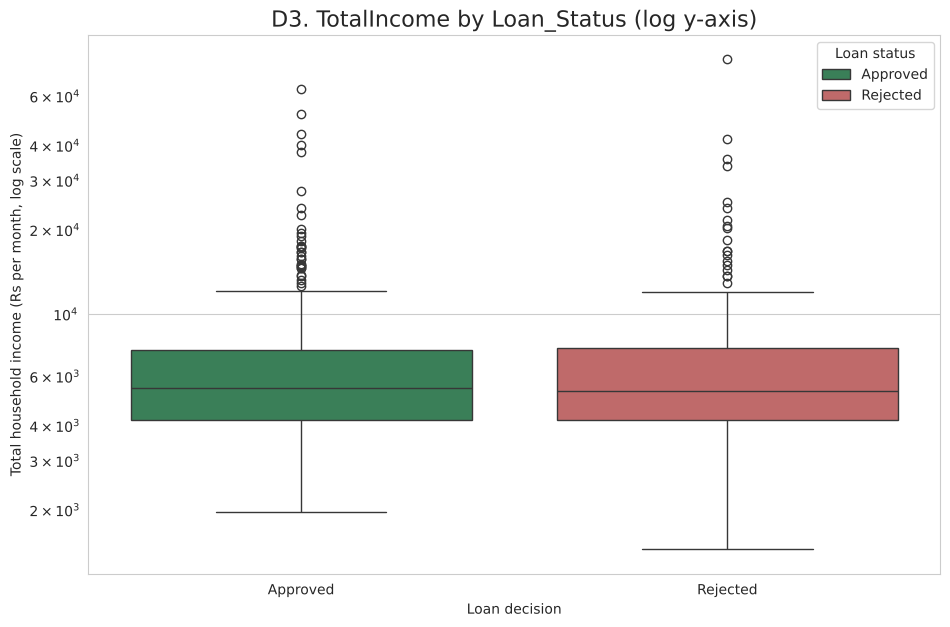

             count    mean  median
Loan_Status                       
Approved       422  6889.0  5439.0
Rejected       192  7324.0  5290.0

Welch t-test p = 0.487 | Mann-Whitney U p = 0.713

Approval % by income quartile:
Income_Band
Q1 Low          67.7
Q2 Lower-mid    68.4
Q3 Upper-mid    71.2
Q4 High         67.5
Name: Approved, dtype: float64


In [27]:
plt.figure(figsize=(11,7))
sns.boxplot(x='Loan_Status', y='TotalIncome', hue='Loan_Status', data=df, order=['Approved','Rejected'],
            palette={'Approved':'seagreen','Rejected':'indianred'}, legend=True)
plt.yscale('log')
plt.title('D3. TotalIncome by Loan_Status (log y-axis)', fontsize=16)
plt.xlabel('Loan decision')
plt.ylabel('Total household income (Rs per month, log scale)')
plt.legend(title='Loan status')
plt.show()

print(df.groupby('Loan_Status')['TotalIncome'].agg(['count','mean','median']).round(0))
a = df.loc[df['Loan_Status']=='Approved','TotalIncome']
r = df.loc[df['Loan_Status']=='Rejected','TotalIncome']
t, p_t = stats.ttest_ind(a, r, equal_var=False)
u, p_u = stats.mannwhitneyu(a, r)
print(f'\nWelch t-test p = {p_t:.3f} | Mann-Whitney U p = {p_u:.3f}')

# approval rate in each income quartile
print('\nApproval % by income quartile:')
print((df.groupby('Income_Band', observed=True)['Approved'].mean()*100).round(1))

**Insight — D3: TotalIncome × Loan_Status**
- **Observation:** **No meaningful difference.** The median household income is ₹5,439 for approved and ₹5,290 for rejected applicants, a gap of 3%. The mean is actually *higher* for rejected applicants (₹7,324 vs ₹6,889). The Welch t-test (p = 0.49) and Mann-Whitney test (p = 0.71) are both not significant.
- **Hidden insight:** **This reverses my A5 expectation.** Approval is flat across income quartiles (67.7%, 68.4%, 71.2%, 67.5%), so the richest quartile does no better than the poorest. Rejected applicants include several high earners, which suggests they were rejected for credit or affordability reasons, not for low income.
- **Business meaning:** Targeting "high-income" customers will not raise conversion by itself.
- **Next step:** Income may matter only *relative to the loan* (EMI burden, D4) or only when there is no co-applicant (E1). Property area may also be a third variable.

### D4. Numeric × Categorical: `LoanAmount` and `EMI_to_Income` across `Loan_Status`
**Question:** Are bigger or less affordable loans rejected more often?

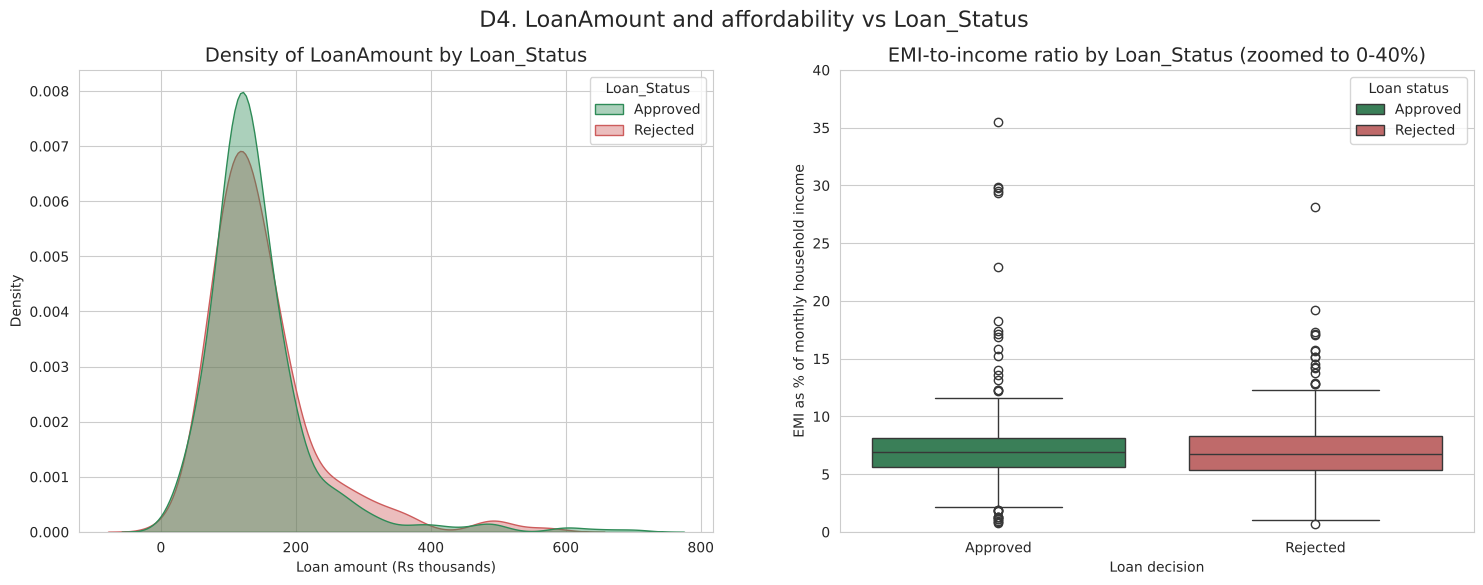

            LoanAmount        EMI_to_Income       
                  mean median          mean median
Loan_Status                                       
Approved        143.97  128.0          7.47   6.91
Rejected        149.71  129.5          8.30   6.78
LoanAmount: Welch t-test p = 0.433, Mann-Whitney p = 0.461
EMI_to_Income: Welch t-test p = 0.295, Mann-Whitney p = 0.855

Approval % by EMI-to-income band:
          count  mean
EMI_Band             
<5%         106  66.0
5-10%       445  71.9
10-15%       39  48.7
>15%         22  54.5


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(18,6))
sns.kdeplot(data=df, x='LoanAmount', hue='Loan_Status', common_norm=False, fill=True, alpha=0.4,
            palette={'Approved':'seagreen','Rejected':'indianred'}, ax=axes[0])
axes[0].set_title('Density of LoanAmount by Loan_Status', fontsize=14)
axes[0].set_xlabel('Loan amount (Rs thousands)')
axes[0].set_ylabel('Density')

sns.boxplot(x='Loan_Status', y='EMI_to_Income', hue='Loan_Status', data=df, order=['Approved','Rejected'],
            palette={'Approved':'seagreen','Rejected':'indianred'}, legend=True, ax=axes[1])
axes[1].set_ylim(0, 40)        # zoom in; a few extreme ratios above 40% are hidden from view, not from the stats
axes[1].set_title('EMI-to-income ratio by Loan_Status (zoomed to 0-40%)', fontsize=14)
axes[1].set_xlabel('Loan decision')
axes[1].set_ylabel('EMI as % of monthly household income')
axes[1].legend(title='Loan status')
plt.suptitle('D4. LoanAmount and affordability vs Loan_Status', fontsize=16)
plt.show()

print(df.groupby('Loan_Status')[['LoanAmount','EMI_to_Income']].agg(['mean','median']).round(2))
for col in ['LoanAmount', 'EMI_to_Income']:
    a = df.loc[df['Loan_Status']=='Approved', col]
    r = df.loc[df['Loan_Status']=='Rejected', col]
    print(f'{col}: Welch t-test p = {stats.ttest_ind(a, r, equal_var=False)[1]:.3f}, Mann-Whitney p = {stats.mannwhitneyu(a, r)[1]:.3f}')

# approval rate by EMI burden band
df['EMI_Band'] = pd.cut(df['EMI_to_Income'], bins=[0,5,10,15,100], labels=['<5%','5-10%','10-15%','>15%'])
print('\nApproval % by EMI-to-income band:')
print(df.groupby('EMI_Band', observed=True)['Approved'].agg(['count','mean']).assign(mean=lambda x: (x['mean']*100).round(1)))

**Insight — D4: LoanAmount / EMI burden × Loan_Status**
- **Observation:** The *average* differences are tiny:
  - Median loan: ₹128k approved vs ₹129.5k rejected (Mann-Whitney p = 0.46).
  - Median EMI-to-income: 6.91% vs 6.78% (p = 0.86).
  - The mean EMI ratio is a little higher for rejected applicants (8.30% vs 7.47%) because of a tail of over-stretched borrowers.
- **Hidden insight:** The relationship is a **threshold, not a line**. Approval is 71.9% when the EMI takes 5–10% of income, but drops to **48.7%** at 10–15% and 54.5% above 15%. Only 61 applicants (10%) are above 10%, which is why averages and correlations miss the effect.
- **Business meaning:** An affordability cap of about 10% of income (on this interest-free measure) marks where the risk rises.
- **Next step:** Check whether the threshold survives after controlling for credit history (E3).

### D5. (Optional) Categorical × Categorical: `Property_Area` × `Loan_Status`
**Question:** Does approval differ by property location?

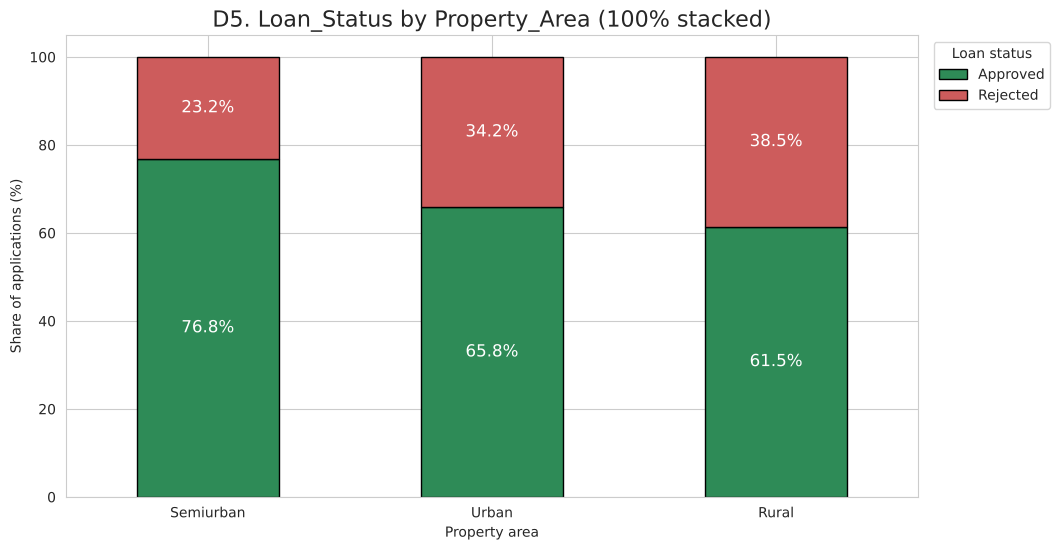

Loan_Status    Approved  Rejected
Property_Area                    
Rural               110        69
Semiurban           179        54
Urban               133        69

Loan_Status    Approved  Rejected
Property_Area                    
Semiurban          76.8      23.2
Urban              65.8      34.2
Rural              61.5      38.5

Chi-square = 12.30, p-value = 0.0021, Cramer's V = 0.14

Credit history mix by area (% Good):
Property_Area
Rural        76.5
Semiurban    80.3
Urban        74.8
Name: Credit_History, dtype: float64


In [29]:
ct = pd.crosstab(df['Property_Area'], df['Loan_Status'])
ct_pct = (pd.crosstab(df['Property_Area'], df['Loan_Status'], normalize='index')*100).sort_values('Approved', ascending=False)

ax = ct_pct.plot(kind='bar', stacked=True, figsize=(11,6), color=['seagreen','indianred'], edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', label_type='center', fontsize=12, color='white')
plt.title('D5. Loan_Status by Property_Area (100% stacked)', fontsize=16)
plt.xlabel('Property area')
plt.ylabel('Share of applications (%)')
plt.xticks(rotation=0)
plt.legend(title='Loan status', bbox_to_anchor=(1.01,1))
plt.show()

print(ct); print(); print(ct_pct.round(1))
chi2, p, dof, exp = stats.chi2_contingency(ct)
print(f'\nChi-square = {chi2:.2f}, p-value = {p:.4f}, Cramer\'s V = {np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1))):.2f}')
print('\nCredit history mix by area (% Good):')
print((df.groupby('Property_Area')['Credit_History'].apply(lambda s: (s=="Good").mean())*100).round(1))

**Insight — D5: Property_Area × Loan_Status**
- **Observation:** There is a **significant but weak-to-moderate** relationship (χ² = 12.3, p = 0.002, Cramér's V = 0.14). Semiurban properties are approved **76.8%** of the time, Urban 65.8% and Rural 61.5%, a gap of 15 points between the best and worst area.
- **Hidden insight:** This **rejects my A5 expectation** that Urban would lead. Semiurban wins, but *not* because of better borrowers: its median household income (₹5,191) is actually the *lowest* of the three areas, and its share of Good credit is only slightly higher (80.3% vs 74.8–76.5%). The area itself seems to matter, perhaps through property valuation or the lender's own focus.
- **Business meaning:** Semiurban is the largest *and* best-converting market.
- **Next step:** Check whether the area effect holds within each credit-history group (E4), since credit history could be the hidden third variable.

### D6. (Optional) Remaining categorical drivers × `Loan_Status`
**Question:** Do marriage, education, self-employment or having a co-applicant change approval?

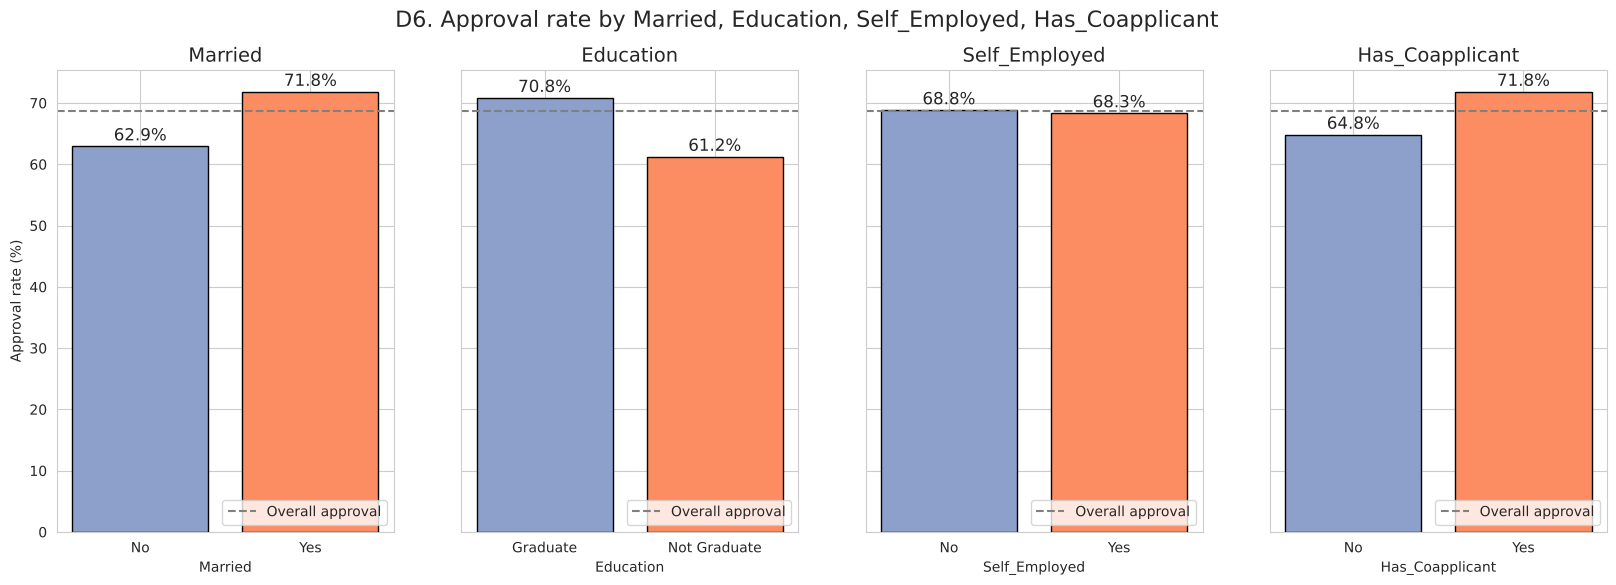

Married          approval %: {'No': 62.9, 'Yes': 71.8}  | chi-square p = 0.030
Education        approval %: {'Graduate': 70.8, 'Not Graduate': 61.2}  | chi-square p = 0.043
Self_Employed    approval %: {'No': 68.8, 'Yes': 68.3}  | chi-square p = 1.000
Has_Coapplicant  approval %: {'No': 64.8, 'Yes': 71.8}  | chi-square p = 0.076


In [30]:
# Approval rate for the remaining categorical drivers, side by side
cols = ['Married', 'Education', 'Self_Employed', 'Has_Coapplicant']
fig, axes = plt.subplots(1, 4, figsize=(20,6), sharey=True)
for i, col in enumerate(cols):
    rate = (df.groupby(col)['Approved'].mean()*100).round(1)
    axes[i].bar(rate.index, rate.values, color=['#8da0cb','#fc8d62'], edgecolor='black')
    for j, v in enumerate(rate.values):
        axes[i].text(j, v+1, f'{v}%', ha='center', fontsize=12)
    axes[i].axhline(df['Approved'].mean()*100, color='grey', linestyle='--', label='Overall approval')
    axes[i].set_title(col, fontsize=14)
    axes[i].set_xlabel(col)
    axes[i].legend(loc='lower right')
axes[0].set_ylabel('Approval rate (%)')
plt.suptitle('D6. Approval rate by Married, Education, Self_Employed, Has_Coapplicant', fontsize=16)
plt.show()

for col in cols:
    ct = pd.crosstab(df[col], df['Loan_Status'])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    print(f'{col:16s} approval %: {(df.groupby(col)["Approved"].mean()*100).round(1).to_dict()}  | chi-square p = {p:.3f}')

**Insight — D6: Married / Education / Self_Employed / Has_Coapplicant × Loan_Status**
- **Observation:**
  - **Married:** 71.8% vs 62.9% for unmarried (p = 0.03).
  - **Graduates:** 70.8% vs 61.2% for non-graduates (p = 0.04).
  - **Has co-applicant:** 71.8% vs 64.8% (p = 0.08, borderline).
  - **Self-employed:** 68.3% vs 68.8% (p = 1.00), with no effect at all.
- **Hidden insight:** My expectation that self-employed applicants would be penalised is **rejected**. The lender treats them the same as salaried applicants. Being married and having a co-applicant overlap, and both suggest a **second earner** helps by about 7–9 points.
- **Business meaning:** These are second-order effects worth 7–10 points each, much smaller than credit history (72 points).
- **Next step:** Check whether the education effect depends on marital status (E5), and whether the co-applicant effect depends on applicant income (E1).

### D-final. Bivariate summary: ranking the supporting columns
**Question:** Which supporting columns have the strongest link with `Loan_Status`?

In [31]:
# Strength of every supporting column vs Loan_Status, on comparable scales
rank = []
for col in ['Credit_History','Property_Area','Married','Education','Self_Employed','Has_Coapplicant','Gender','Dependents']:
    ct = pd.crosstab(df[col], df['Loan_Status'])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    rank.append([col, 'Categorical', "Cramer's V", round(np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1))),3), round(p,4)])
for col in ['TotalIncome','ApplicantIncome','CoapplicantIncome','LoanAmount','EMI_to_Income','Loan_Amount_Term']:
    r, p = stats.pointbiserialr(df['Approved'], df[col])      # correlation between a 0/1 variable and a numeric one
    rank.append([col, 'Numeric', 'Point-biserial r', round(r,3), round(p,4)])
rank = pd.DataFrame(rank, columns=['Column','Type','Measure','Strength','p-value'])
rank['abs'] = rank['Strength'].abs()
rank = rank.sort_values('abs', ascending=False).drop(columns='abs').reset_index(drop=True)
rank

,Column,Type,Measure,Strength,p-value
0,Credit_History,Categorical,Cramer's V,0.542,0.0000
1,Property_Area,Categorical,Cramer's V,0.142,0.0021
2,Married,Categorical,Cramer's V,0.088,0.0296
3,Education,Categorical,Cramer's V,0.082,0.0431
4,Has_Coapplicant,Categorical,Cramer's V,0.072,0.0759
5,Dependents,Categorical,Cramer's V,0.072,0.3689
6,CoapplicantIncome,Numeric,Point-biserial r,-0.059,0.1429
7,EMI_to_Income,Numeric,Point-biserial r,-0.049,0.2268
8,LoanAmount,Numeric,Point-biserial r,-0.032,0.4342
9,TotalIncome,Numeric,Point-biserial r,-0.031,0.4392


**Ranking, strongest to weakest relationship with `Loan_Status`:**
1. **Credit_History:** Cramér's V = 0.54. Approval is 79.6% for Good vs 7.9% for Bad (D2). This is dominant.
2. **Property_Area:** V = 0.14. Approval is 76.8% for Semiurban vs 61.5% for Rural (D5).
3. **Married:** V = 0.09. Approval is 71.8% vs 62.9% (D6).
4. **Education:** V = 0.08. Approval is 70.8% for graduates vs 61.2% (D6).
5. **Has_Coapplicant / CoapplicantIncome:** V = 0.07, p = 0.08. Approval is 71.8% vs 64.8% (D6). This is borderline.
6. **EMI_to_Income:** r = −0.05 overall, but approval drops to 48.7% above a 10% burden (D4). The effect is a threshold, not a linear relationship.
7. **LoanAmount and TotalIncome / ApplicantIncome:** |r| ≤ 0.03, p > 0.4 (D3, D4). There is no direct relationship.
8. **Self_Employed:** V = 0.00, p = 1.0. There is no relationship.

---
# Section E: Multivariate analysis
Every combination includes the primary column. For E1 and E5, the primary column is used in its **numeric 1/0 form (`Approved`)**. Its average is the **approval rate**, which is the only way a binary outcome can be shown as a colour scale or a bar height.

### E1. Three numeric: `ApplicantIncome` × `CoapplicantIncome` × `Approved`
**Question:** Does a co-applicant's income matter more for some applicant-income levels than for others?

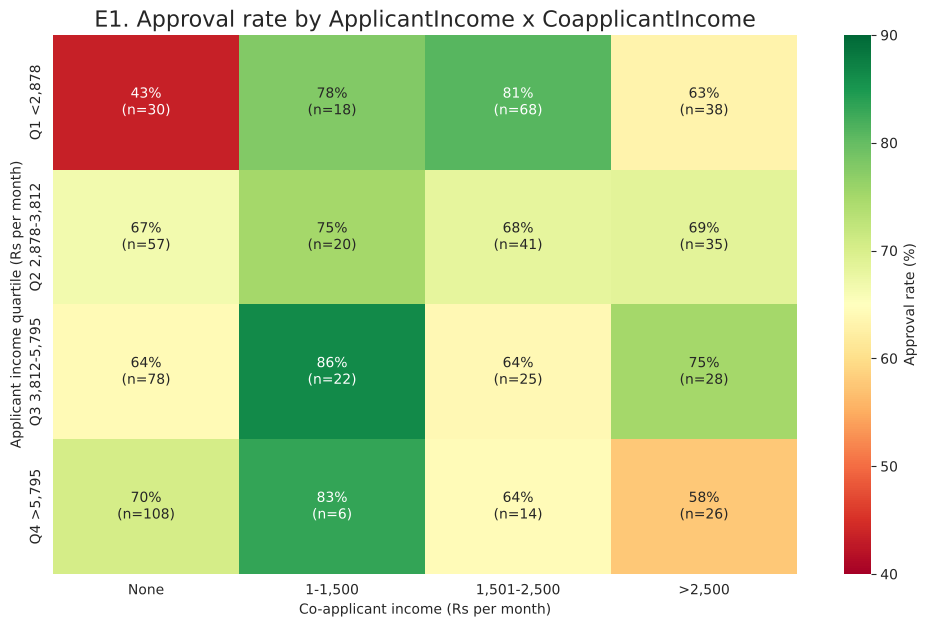

Correlation matrix (Spearman) of the three variables:
                   ApplicantIncome  CoapplicantIncome  Approved
ApplicantIncome              1.000             -0.320    -0.004
CoapplicantIncome           -0.320              1.000     0.035
Approved                    -0.004              0.035     1.000

Approval rate table (%):
Coapp           None  1-1,500  1,501-2,500  >2,500
Applicant_Band                                    
Q1 <2,878       43.3     77.8         80.9    63.2
Q2 2,878-3,812  66.7     75.0         68.3    68.6
Q3 3,812-5,795  64.1     86.4         64.0    75.0
Q4 >5,795       70.4     83.3         64.3    57.7

Count table:
Coapp           None  1-1,500  1,501-2,500  >2,500
Applicant_Band                                    
Q1 <2,878         30       18           68      38
Q2 2,878-3,812    57       20           41      35
Q3 3,812-5,795    78       22           25      28
Q4 >5,795        108        6           14      26


In [32]:
# Three numeric columns: ApplicantIncome, CoapplicantIncome, Approved (1/0 form of the primary column)
# Incomes are cut into bands only for the heatmap; the colour is the mean of Approved = approval rate
df['Applicant_Band'] = pd.qcut(df['ApplicantIncome'], q=4, labels=['Q1 <2,878','Q2 2,878-3,812','Q3 3,812-5,795','Q4 >5,795'])
coapp_simple = pd.cut(df['CoapplicantIncome'], bins=[-1,0,1500,2500,50000], labels=['None','1-1,500','1,501-2,500','>2,500'])

rate = pd.pivot_table(df.assign(Coapp=coapp_simple), values='Approved', index='Applicant_Band', columns='Coapp',
                      aggfunc='mean', observed=False)*100
count = pd.pivot_table(df.assign(Coapp=coapp_simple), values='Approved', index='Applicant_Band', columns='Coapp',
                       aggfunc='count', observed=False)

plt.figure(figsize=(12,7))
annot = rate.round(0).astype(int).astype(str) + '%\n(n=' + count.astype(int).astype(str) + ')'
sns.heatmap(rate, annot=annot, fmt='', cmap='RdYlGn', vmin=40, vmax=90, cbar_kws={'label':'Approval rate (%)'})
plt.title('E1. Approval rate by ApplicantIncome x CoapplicantIncome', fontsize=16)
plt.xlabel('Co-applicant income (Rs per month)')
plt.ylabel('Applicant income quartile (Rs per month)')
plt.show()

print('Correlation matrix (Spearman) of the three variables:')
print(df[['ApplicantIncome','CoapplicantIncome','Approved']].corr(method='spearman').round(3))
print('\nApproval rate table (%):'); print(rate.round(1))
print('\nCount table:'); print(count)

**Insight — E1: ApplicantIncome × CoapplicantIncome × Approved**
- **Observation:** In the correlation matrix, both incomes are almost uncorrelated with `Approved` (ρ = −0.004 and 0.035). The two incomes are negatively related to each other (ρ = −0.32): low earners bring earning partners.
- **Hidden insight (interaction):** The heatmap shows what the correlations hide. For the **lowest applicant-income quartile with no co-applicant**, approval is only **43.3%** (n = 30, 4.9% of applications). With *any* co-applicant income, that same quartile jumps to **75.0%** (n = 124). For the top quartile, a co-applicant adds nothing (70.4% without vs 63.0% with).
- **Business meaning:** A co-applicant is a **substitute for low personal income**, not a general booster. A manager looking at D3 would conclude "income doesn't matter", but it does matter for low-income solo applicants.
- **Action:** Ask low-income single applicants to add an earning co-applicant before submitting.

### E2. Two numeric + one categorical: `TotalIncome` × `LoanAmount` × `Loan_Status`
**Question:** Do approved and rejected applicants size their loans to income in the same way?

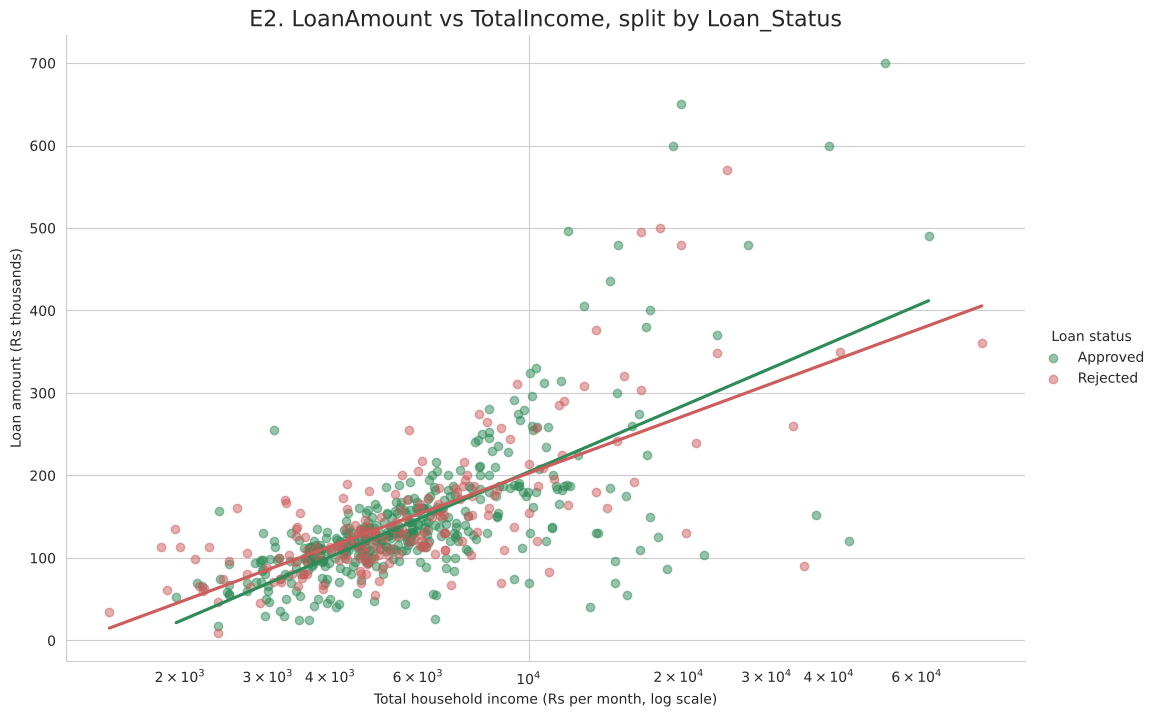

  Loan_Status    n  Pearson r  Spearman rho  \
0    Approved  422      0.652         0.696   
1    Rejected  192      0.585         0.683   

   Median loan / median monthly income  
0                                 23.5  
1                                 24.5  


In [33]:
g = sns.lmplot(x='TotalIncome', y='LoanAmount', hue='Loan_Status', data=df, height=7, aspect=1.5,
               palette={'Approved':'seagreen','Rejected':'indianred'}, scatter_kws={'alpha':0.5}, logx=True, ci=None)
g.ax.set_xscale('log')
g.ax.set_title('E2. LoanAmount vs TotalIncome, split by Loan_Status', fontsize=16)
g.ax.set_xlabel('Total household income (Rs per month, log scale)')
g.ax.set_ylabel('Loan amount (Rs thousands)')
g._legend.set_title('Loan status')
plt.show()

# Correlation of the two numerics inside each class of the primary column
rows = []
for status in ['Approved','Rejected']:
    sub = df[df['Loan_Status']==status]
    rows.append([status, len(sub), round(stats.pearsonr(sub['TotalIncome'], sub['LoanAmount'])[0],3),
                 round(stats.spearmanr(sub['TotalIncome'], sub['LoanAmount'])[0],3),
                 round(sub['LoanAmount'].median()*1000/sub['TotalIncome'].median(),1)])
print(pd.DataFrame(rows, columns=['Loan_Status','n','Pearson r','Spearman rho','Median loan / median monthly income']))

**Insight — E2: TotalIncome × LoanAmount × Loan_Status**
- **Observation:** The two trend lines almost **overlap**. Within each group, income and loan size are similarly correlated (approved r = 0.65, rejected r = 0.59; Spearman 0.70 vs 0.68). Median loan ÷ median monthly income is 23.5× for approved and 24.5× for rejected applicants.
- **Hidden insight:** The relationship from D1 neither strengthens nor reverses within groups, and there is **no Simpson's paradox**. Rejected applicants are *not* asking for loans out of proportion to their income. Their points are slightly more scattered (lower r), which means a few over-sized requests, but these are the minority.
- **Business meaning:** Most rejections are not about the loan-to-income sizing the customer chose. This points again to credit history as the main reason.
- **Next step:** Hold credit history constant and re-check affordability (E3).

### E3. One numeric + two categorical: `EMI_to_Income` × `Credit_History` × `Loan_Status`
**Question:** Once credit history is held constant, does a heavier EMI burden lead to rejection?

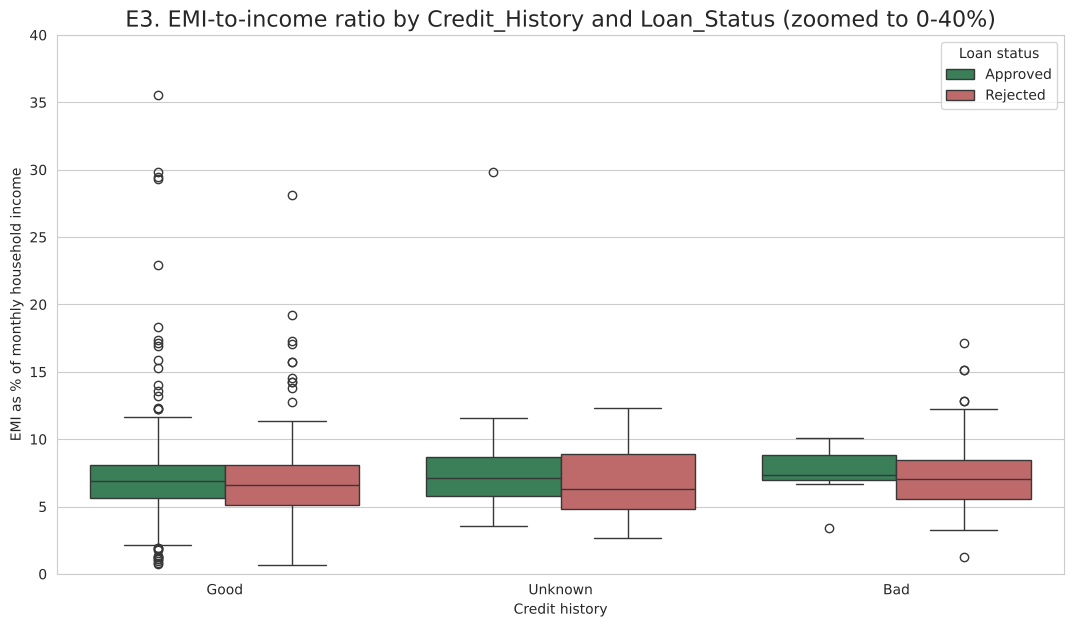

                 median             count         
Loan_Status    Approved Rejected Approved Rejected
Credit_History                                    
Good               6.89     6.63      378       97
Unknown            7.09     6.31       37       13
Bad                7.34     7.08        7       82

Good credit history only - approval % by EMI band:
          count  mean
EMI_Band             
<5%          87  74.7
5-10%       342  83.6
10-15%       27  59.3
>15%         18  61.1
Mann-Whitney p (good credit, approved vs rejected EMI ratio) = 0.794


In [34]:
plt.figure(figsize=(13,7))
sns.boxplot(x='Credit_History', y='EMI_to_Income', hue='Loan_Status', data=df, order=['Good','Unknown','Bad'],
            palette={'Approved':'seagreen','Rejected':'indianred'})
plt.ylim(0, 40)
plt.title('E3. EMI-to-income ratio by Credit_History and Loan_Status (zoomed to 0-40%)', fontsize=16)
plt.xlabel('Credit history')
plt.ylabel('EMI as % of monthly household income')
plt.legend(title='Loan status')
plt.show()

pv = pd.pivot_table(df, values='EMI_to_Income', index='Credit_History', columns='Loan_Status',
                    aggfunc=['median','count']).round(2)
print(pv.loc[['Good','Unknown','Bad']])

# Within GOOD credit history only: does a heavy EMI burden reduce approval?
good = df[df['Credit_History']=='Good']
print('\nGood credit history only - approval % by EMI band:')
print(good.groupby('EMI_Band', observed=True)['Approved'].agg(['count','mean']).assign(mean=lambda x: (x['mean']*100).round(1)))
a = good.loc[good['Loan_Status']=='Approved','EMI_to_Income']; r = good.loc[good['Loan_Status']=='Rejected','EMI_to_Income']
print(f'Mann-Whitney p (good credit, approved vs rejected EMI ratio) = {stats.mannwhitneyu(a, r)[1]:.3f}')

**Insight — E3: EMI_to_Income × Credit_History × Loan_Status**
- **Observation:** Within every credit group, the *median* EMI burden is almost the same for approved and rejected applicants (Good: 6.89% vs 6.63%; Bad: 7.34% vs 7.08%; Mann-Whitney p = 0.79 for Good). The boxes overlap almost completely.
- **Hidden insight (interaction):** Among **Good-history** applicants, approval is **83.6%** at a 5–10% burden but falls to **59.3%** at 10–15% and **61.1%** above 15%. The threshold from D4 *survives* controlling for credit, so it is a real second filter. These 45 over-stretched Good-history applicants (7.3% of all applications) lose about 24 points. Many of them took **180-month** terms, which raise the EMI.
- **Business meaning:** A manager who only looks at medians would miss this over-stretched sub-group.
- **Action:** Offer a longer tenure or a smaller ticket to Good-history applicants whose EMI exceeds 10% of income.

### E4. (Optional) One numeric + two categorical: `Approved` × `Credit_History` × `Property_Area`
**Question:** Does the Semiurban advantage hold within each credit-history group?

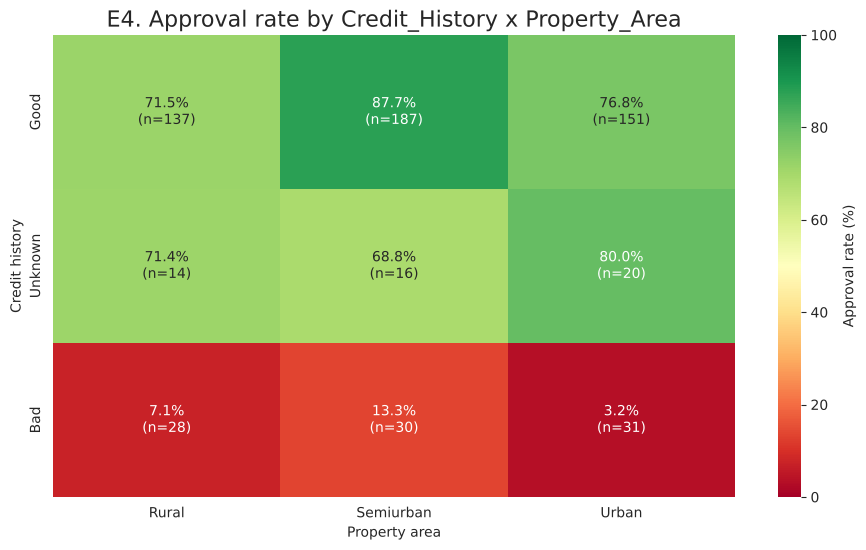

Approval rate (%):
Property_Area   Rural  Semiurban  Urban
Credit_History                         
Good             71.5       87.7   76.8
Unknown          71.4       68.8   80.0
Bad               7.1       13.3    3.2

Count:
Property_Area   Rural  Semiurban  Urban
Credit_History                         
Good              137        187    151
Unknown            14         16     20
Bad                28         30     31

Segment share of all applications (%):
Property_Area   Rural  Semiurban  Urban
Credit_History                         
Good             22.3       30.5   24.6
Unknown           2.3        2.6    3.3
Bad               4.6        4.9    5.0


In [35]:
rate = pd.pivot_table(df, values='Approved', index='Credit_History', columns='Property_Area', aggfunc='mean')*100
count = pd.pivot_table(df, values='Approved', index='Credit_History', columns='Property_Area', aggfunc='count')
rate, count = rate.loc[['Good','Unknown','Bad']], count.loc[['Good','Unknown','Bad']]

plt.figure(figsize=(11,6))
annot = rate.round(1).astype(str) + '%\n(n=' + count.astype(str) + ')'
sns.heatmap(rate, annot=annot, fmt='', cmap='RdYlGn', vmin=0, vmax=100, cbar_kws={'label':'Approval rate (%)'})
plt.title('E4. Approval rate by Credit_History x Property_Area', fontsize=16)
plt.xlabel('Property area')
plt.ylabel('Credit history')
plt.show()

print('Approval rate (%):'); print(rate.round(1))
print('\nCount:'); print(count)
print('\nSegment share of all applications (%):'); print((count/len(df)*100).round(1))

**Insight — E4: Approved × Credit_History × Property_Area**
- **Observation:** Credit history still dominates every area: Bad history is approved only 3.2–13.3% of the time anywhere. Within Good history, **Semiurban is approved 87.7%** of the time against Urban 76.8% and Rural 71.5%.
- **Hidden insight:** The area effect **strengthens** within Good-history applicants (a 16-point Semiurban vs Rural gap) and **reverses** within "Unknown" (Urban 80.0% is best, Semiurban 68.8% is worst, although n is only 14–20 per cell).
- **Segments:**
  - **Best:** Good credit + Semiurban. 187 applications, 30.5% of all, approved 87.7%.
  - **Worst:** Bad credit + Urban. 31 applications, 5.0% of all, approved 3.2%.
- **Business meaning:** Area is a real second driver, *on top of* credit history, not a disguised credit effect.
- **Action:** Focus sales effort on the Good-credit Semiurban segment. Review why Good-credit **Rural** applicants (137, 22.3%) are rejected 28.5% of the time, for example because of property title or valuation issues.

### E5. (Optional) One numeric + two categorical: `Approved` × `Married` × `Education`
**Question:** Does the graduate advantage depend on marital status?

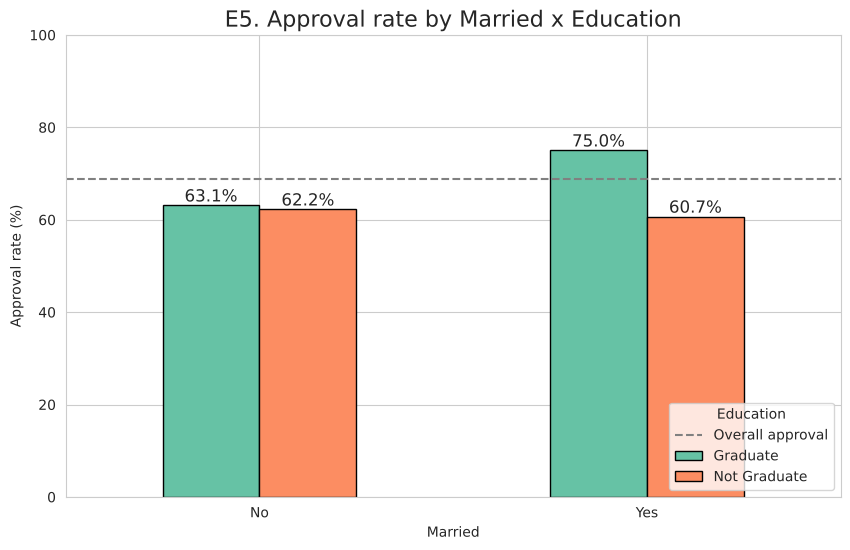

Approval rate (%):
Education  Graduate  Not Graduate
Married                          
No             63.1          62.2
Yes            75.0          60.7

Count:
Education  Graduate  Not Graduate
Married                          
No              168            45
Yes             312            89

Segment share of all applications (%):
Education  Graduate  Not Graduate
Married                          
No             27.4           7.3
Yes            50.8          14.5


In [36]:
# Approved (numeric 1/0) x Married x Education
rate = pd.pivot_table(df, values='Approved', index='Married', columns='Education', aggfunc='mean')*100
count = pd.pivot_table(df, values='Approved', index='Married', columns='Education', aggfunc='count')

fig, ax = plt.subplots(figsize=(10,6))
rate.plot(kind='bar', ax=ax, color=['#66c2a5','#fc8d62'], edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', fontsize=12)
ax.axhline(df['Approved'].mean()*100, color='grey', linestyle='--', label='Overall approval')
plt.title('E5. Approval rate by Married x Education', fontsize=16)
plt.xlabel('Married')
plt.ylabel('Approval rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Education', loc='lower right')
plt.show()

print('Approval rate (%):'); print(rate.round(1))
print('\nCount:'); print(count)
print('\nSegment share of all applications (%):'); print((count/len(df)*100).round(1))

**Insight — E5: Approved × Married × Education**
- **Observation:** Among **unmarried** applicants, education makes **no difference** (Graduate 63.1% vs Not Graduate 62.2%). Among **married** applicants, graduates are approved **75.0%** of the time against 60.7% for non-graduates, a 14-point gap.
- **Hidden insight (interaction):** The education effect seen in D6 (9.6 points overall) comes almost entirely from married applicants. The likely mechanism is that a married graduate household tends to have **two stable incomes**. Married non-graduates (89 applicants, 14.5%) are approved *less* than unmarried applicants, so marriage alone does not help.
- **Segment:** Married graduates are 312 applications (50.8% of the total) with a 75.0% approval rate. This is the largest high-approval demographic group.
- **Business meaning:** A manager who looked at Married and Education separately would over-credit both.
- **Action:** Check co-applicant income for married non-graduates rather than assuming two earners.

### E-final. Multivariate summary: the most important segments
- **Best segment:** Applicants with **Good credit history and a Semiurban property** (187 applications, 30.5% of all) are approved **87.7%** of the time, against 68.7% overall.
- **Over-stretched good borrowers:** Applicants with **Good credit history but an EMI above 10% of household income** (45 applications, 7.3%) are approved only **about 60%** of the time, against 83.6% for Good-history applicants at a 5–10% burden.
- **Low-income solo applicants:** **Bottom-quartile applicant income (< ₹2,878 a month) with no co-applicant** (30 applications, 4.9%) are approved only **43.3%** of the time. The same income band with a co-applicant reaches 75.0%.
- *(Floor segment)* **Bad credit history in any area** (89 applications, 14.5%) is approved **7.9%** of the time.

---
# Section F: Consolidated conclusion

### F1. Executive summary
- **Credit history decides most outcomes.** Good-history applicants are approved 79.6% of the time and Bad-history ones 7.9% (Cramér's V = 0.54, p < 0.001).
- **Income and loan size do not predict approval directly.** Median household income is ₹5,439 for approved vs ₹5,290 for rejected applicants (p = 0.71), and median loan is ₹128k vs ₹129.5k (p = 0.46).
- **Affordability works as a threshold.** With Good credit, approval falls from 83.6% to about 60% once the EMI exceeds 10% of income.
- **Location is the second driver.** Semiurban properties are approved 76.8% of the time vs 61.5% for Rural, and Good-credit Semiurban reaches 87.7%.
- **A co-applicant helps only low earners.** In the bottom income quartile, approval rises from 43.3% to 75.0% with a co-applicant.
- **Self-employment has no effect** (68.3% vs 68.8%). The graduate advantage exists only among married applicants.

### F2. Expectation scorecard

| A5 expectation | Verdict | Evidence |
|---|---|---|
| Good credit → higher approval | Confirmed | D2: 79.6% vs 7.9%, V = 0.54 |
| Higher income → higher approval | Rejected | D3: Mann-Whitney p = 0.71; quartiles 67.5–71.2% |
| Larger loan → more rejections | Partly supported | D4: amount p = 0.46, but EMI > 10% → 48.7% |
| Co-applicant → higher approval | Partly supported | D6: p = 0.08; E1: 43.3% → 75.0% in Q1 only |
| Urban → highest approval | Rejected | D5: Semiurban 76.8% > Urban 65.8% |
| Graduates → higher approval | Partly supported | D6: p = 0.04; E5: no gap if unmarried |
| Married → higher approval | Confirmed (weak) | D6: 71.8% vs 62.9%, V = 0.09 |
| Self-employed → lower approval | Rejected | D6: p = 1.00 |

### F3. Key drivers of `Loan_Status`
1. **Credit history (the gatekeeper).** No area pushes Bad-credit approval above 13.3% (E4).
2. **Property area.** Within Good credit, Semiurban is approved 87.7% of the time vs 71.5% for Rural. Income and credit mix do not explain this (D5).
3. **EMI burden above about 10% of income.** The effect is invisible in averages but survives controlling for credit history (E3).
4. **A second earner.** A co-applicant compensates for low applicant income (E1) and explains why married graduates do best (E5).

**How they interact:** Approval works as a **sequence of filters**. Credit history comes first. After that, location and repayment capacity decide the rest. Income alone shows no effect because it matters only relative to the loan size and the number of earners.

### F4. Business recommendations for the Head of Retail Lending
1. **Check the credit bureau at the start of the online form.**
   - *Segment:* Bad-history applicants (14.5%).
   - *Action:* redirect them to a credit-builder or secured product before full processing.
   - *Impact:* 82 of the 192 rejections (43%) leave the processing queue. First-time borrowers ("Unknown", 74% approval) stay in the normal process.
2. **Add an affordability nudge.**
   - *Segment:* Good-history applicants whose EMI exceeds 10% of income (45 applications, about 60% approved).
   - *Action:* automatically suggest a longer tenure or a smaller loan amount.
   - *Impact:* reaching their peers' 83.6% rate would add about 10 approvals per 614 applications, roughly +1.7 points on the overall approval rate.
3. **Focus on Semiurban and fix Rural.**
   - *Segment:* Good-credit Semiurban (30.5% of applications) for marketing; Good-credit Rural (71.5% approval) for review.
   - *Action:* shift marketing budget to Semiurban, audit Rural rejections for property-document issues, and prompt low-income solo applicants to add a co-applicant.
   - *Impact:* higher conversion per marketing rupee and fewer good customers lost.

### F5. Limitations and next steps
**Limitations**
- **Small segments:** One lender's 614 undated applications. Some segments are small (14–45 rows), so their percentages are uncertain.
- **Imputation choices:** I imputed up to 5% of some columns and created an "Unknown" credit level. Different choices could shift small segments.
- **EMI measure:** EMI ignores interest, so the 10% threshold is only relative.
- **Outliers kept:** Keeping all outliers adds noise to means, which is why I relied on medians and non-parametric tests.
- **Correlation, not causation:** The Semiurban effect may reflect property value or lender policy that is not in the data. The data shows past *decisions*, not actual defaults.

**Next steps**
1. Build a logistic regression or decision tree to estimate each driver's effect while holding the others fixed.
2. Add interest rates, existing EMIs, loan-to-value and default data.
3. A/B test the tenure nudge from Recommendation 2.

---
### AI and source declaration
- **Dataset:** Loan Prediction Problem Dataset, Kaggle (https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset), originally from the Analytics Vidhya "Loan Prediction" practice problem (Dream Housing Finance).
- **Coding style:** Based on the Python class notebook from our course sessions (`pd.read_excel`, `sns.histplot`, `plt.boxplot`, `sns.countplot`, `sns.regplot` with `plt.title`/`xlabel`/`ylabel`).
- **Libraries:** pandas, NumPy, Matplotlib and Seaborn for analysis and charts. `scipy.stats` is used only to compute test statistics (chi-square, t-test, Mann-Whitney, Pearson/Spearman, point-biserial).
- **Generative AI:** Claude (Anthropic) was used as a learning and coding aid: help with code structure, debugging, and checking that each chart has a title, axis units and a legend. All insights were checked against the outputs printed in this notebook.